# Label-Conditioned Robot Vision  
### A Baseline Study in Controlled Visual Generation for Robotics

---

## Abstract

Robotic systems rely heavily on vision modules to interpret and interact with the physical world. In many robotics pipelines, visual perception is not unconstrained; instead, it is guided by **explicit semantic priors** such as object categories, task labels, or scene identifiers. This project investigates **Label-Conditioned Robot Vision**, where symbolic class information is used to control visual generation, and studies its behavior as a **baseline perception module**.

Using Conditional Generative Adversarial Networks (cGANs), we model the mapping from **semantic labels → visual observations**, treating label conditioning as an abstraction of high-level robotic knowledge (e.g., object class hypotheses). The goal is not photorealistic synthesis, but rather to evaluate **controllability, training stability, failure modes, and scalability** of label-conditioned vision across increasing dataset complexity.

Experiments are conducted progressively on MNIST, Oxford-102 Flowers, and CUB-200 Birds to analyze how label-conditioned vision behaves under varying class cardinality, visual entropy, and background noise—conditions commonly encountered in robotic perception tasks.

---

## 1. Motivation and Robotics Context

In Robotics and Autonomous Systems, perception modules often operate under **structured constraints**:

- Object categories are known or hypothesized (e.g., tool type, obstacle class)
- Tasks impose semantic expectations (e.g., “find a flower”, “detect a bird-like object”)
- Vision is one component within a larger autonomy stack

Rather than learning unconstrained image generation, this project focuses on **controlled visual generation**, where semantic labels explicitly guide the visual output. This framing aligns with robotics use cases such as:

- Perception prototyping before full deployment
- Synthetic data generation for rare classes
- Studying failure modes in semantic vision systems
- Understanding how symbolic information influences visual representations

The project therefore reframes cGANs not as artistic generators, but as **robot vision primitives**.

---

## 2. Problem Formulation

We model robot vision as a conditional generative process:

$$
z \sim \mathcal{N}(0, I), \quad y \in \{0,1\}^K
$$

where:
- $ z $ is a latent noise vector representing stochastic visual variability
- $ y $ is a one-hot encoded semantic label (class prior)
- $ x $ is a generated visual observation (image)

The generator learns a mapping:
$$
G: (z, y) \rightarrow x
$$

The discriminator learns to distinguish real vs generated samples under the same conditioning:
$$
D: (x, y) \rightarrow [0,1]
$$

This formulation mirrors robotics perception settings where:
- $ y $ represents symbolic or semantic context
- $ x $ represents sensor observations
- The system must respect both realism and semantic alignment

---

## 3. Mathematical Modeling

### 3.1 Conditional GAN Objective

The adversarial objective is given by:

$$
\min_G \max_D \; \mathbb{E}_{x,y \sim p_{\text{data}}}[\log D(x,y)] +
\mathbb{E}_{z \sim p(z), y \sim p(y)}[\log(1 - D(G(z,y),y))]
$$

This objective enforces two constraints critical to robot vision:
1. **Visual plausibility** (generated images resemble sensor data)
2. **Semantic consistency** (generated images match the conditioning label)

Binary Cross-Entropy (BCE) loss is used throughout, reflecting a standard and interpretable baseline for adversarial training.

---

## 4. System Architecture (Robotics Perspective)

### Generator (Vision Synthesis Module)
- Inputs: latent noise $ z $ + semantic label $ y $
- Outputs: synthetic visual observation $ x $
- Architecture scales with dataset complexity:
  - Fully connected layers for MNIST (28×28 grayscale)
  - Convolutional upsampling for Oxford-102 (64×64 RGB)
  - Deeper convolutional architecture for CUB-200 (96×96 RGB)

### Discriminator (Vision Consistency Verifier)
- Inputs: image $ x $ + semantic label $ y $
- Output: realism score (real vs fake)
- Acts as a learned consistency check between visual structure and semantic label

This generator–discriminator pairing can be interpreted as:
> *A vision module producing hypotheses and a verifier enforcing semantic plausibility.*

---

## 5. Execution Pipeline

The project follows a structured robotics-style experimental pipeline:

1. **Dataset Preparation**
   - Normalize and resize images to fixed sensor resolutions
   - Encode labels as one-hot semantic priors

2. **Model Initialization**
   - Generator and Discriminator instantiated per dataset
   - Architecture complexity matched to visual entropy

3. **Offline Training**
   - Adversarial training using Adam optimizer
   - Fixed noise + labels used for consistent monitoring
   - Training loops are intentionally marked “DO NOT RUN” unless retraining is desired

4. **Evaluation**
   - Qualitative inspection of generated samples
   - Quantitative metrics:
     - FID (distributional similarity)
     - Inception Score (class separability)

5. **Analysis**
   - Loss dynamics (G vs D imbalance)
   - Mode confusion and semantic leakage
   - Resolution and dataset bias effects

---

## 6. Datasets as Perception Stress Tests

Each dataset is treated as a **robot vision stress test**, not just a benchmark:

- **MNIST**  
  Sanity check for label-conditioned visual controllability.

- **Oxford-102 Flowers**  
  Tests fine-grained category separation under class imbalance and color/texture variance.

- **CUB-200 Birds**  
  High-entropy visual environment with background clutter, pose variation, and semantic overlap—analogous to real-world robotic perception challenges.

---

## 7. Purpose of the Project

This project is intentionally positioned as a **baseline**. Its purpose is to:

- Validate label-conditioned vision as a controllable perception primitive
- Identify limitations before scaling to higher-capacity models
- Build intuition for semantic conditioning in robotic vision systems
- Serve as a precursor to:
  - embedding-based conditioning
  - diffusion models
  - world models
  - sim-to-real data generation pipelines

---

## 8. Expected Deliverables

By the end of this project, the following deliverables are produced:

- A fully reproducible notebook implementing label-conditioned robot vision
- Trained generators and discriminators for all datasets
- Saved visual outputs demonstrating semantic control
- Quantitative evaluation metrics (FID, Inception Score)
- A structured analysis of:
  - training stability
  - failure modes
  - scalability limits

---

## 9. Scope and Limitations

This work does **not** claim:
- Photorealistic image synthesis
- Deployment-ready perception systems
- Multi-modal sensor fusion

Instead, it deliberately focuses on **controlled, interpretable, and analyzable robot vision behavior** at low-to-moderate resolution.

---

## Summary

### **Label-Conditioned Robot Vision** reframes conditional generative modeling as a robotics perception problem. By emphasizing controllability, semantic grounding, and honest failure analysis, this project provides a solid foundation for more advanced robotic vision and world modeling systems.

---

## Contributions

This project was developed as a collaborative effort, with clear role separation across modeling, experimentation, and analysis.  
The following contributions are acknowledged based on implementation and documentation records:

### **Snavya Sai Munti Mudugu Badri Prasad**
GitHub: https://github.com/snavya0309  

- Reproduction of the original **CGAN baseline (Mirza & Osindero, 2014)** on the MNIST dataset  
- Baseline experimentation and result analysis for MNIST  
- Comparative discussion against the original CGAN formulation  

### **Sushma Niresh**
GitHub: https://github.com/Sushmaniresh  

- Dataset handling and preprocessing pipelines  
- Implementation of **label-conditioning mechanisms**  
- Design and extension of **convolutional cGAN architectures** for Oxford-102 and CUB-200 datasets  

### **Ayushman Mishra**  
GitHub: https://github.com/aymisxx  

- Designed and implemented Generator and Discriminator architectures across datasets  
- Executed end-to-end training, evaluation, and result generation  
- Developed the mathematical formulation and analytical interpretation of the models  
- Led system-level modeling and analysis from a **Robotics & Autonomous Systems** standpoint  
- Managed repository structure, experimentation workflow, documentation, and reproducibility 

---

## **Setting up GPU.**

In [1]:
import torch
print("Device:", torch.cuda.get_device_name(0))

Device: NVIDIA GeForce RTX 4060 Laptop GPU


# **MNIST Original Baseline**

#### Important Modules

In [2]:
!pip install torch torchvision numpy matplotlib pillow tqdm scikit-learn --quiet

### Imports & Setup.

In [3]:
import os, random, json, numpy as np, matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import MNIST
from torchvision.utils import make_grid, save_image

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# reproducibility
torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

Using device: cuda


## MNIST Baseline: Robot Vision Sanity Check Configuration

This section defines the **baseline experimental configuration** for the MNIST dataset, which is used as a **sanity check for label-conditioned robot vision**.

MNIST serves as a low-dimensional, low-entropy visual environment where semantic labels (digits 0–9) have a direct and interpretable correspondence to visual structure. This setup allows us to validate whether a vision module can:

- Respect explicit semantic conditioning  
- Produce visually consistent outputs under controlled settings  
- Exhibit stable training dynamics before scaling to more complex environments  

The parameters below define the **sensor resolution, semantic space, and learning constraints** for this baseline vision module.

Key design choices:
- **Latent Dimension (`z_dim`)** models stochastic visual variability analogous to sensor noise.
- **Label Dimension (`y_dim`)** represents discrete semantic priors available to a robot.
- **Image Dimension (`img_dim`)** reflects a flattened low-resolution camera input (28×28 grayscale).
- **Batch Size and Learning Rate** are selected to balance convergence stability and training efficiency for a baseline study.

This configuration intentionally prioritizes **interpretability and controllability** over visual realism, making it suitable for validating the core mechanics of label-conditioned robot vision before progressing to higher-resolution and higher-entropy datasets.

In [4]:
dataset     = "MNIST"
batch_size  = 100
z_dim       = 100
y_dim       = 10
img_dim     = 784          # 28×28x1 (Greyscale)
lr          = 0.0002
epochs      = 200
save_dir    = "./outputs/MNIST"
os.makedirs(save_dir, exist_ok=True)

## Label-Conditioned Vision Architecture (MNIST Baseline)

This section defines the **Generator–Discriminator architecture** used to model **label-conditioned robot vision** in a low-resolution setting.

From a Robotics perspective, the Generator can be interpreted as a **vision synthesis module** that produces visual observations conditioned on explicit semantic priors, while the Discriminator acts as a **consistency verifier**, ensuring alignment between generated visuals and their corresponding semantic labels.

The MNIST baseline intentionally uses a **fully connected architecture** to maintain architectural simplicity and maximize interpretability. This design choice allows clear analysis of conditioning behavior without the added complexity of spatial feature learning.

---

### Generator: Semantic-to-Visual Mapping Module

The Generator models the mapping:

$$
(z, y) \rightarrow x
$$

where:
- $ z $ represents stochastic variability (analogous to sensor noise or environmental uncertainty),
- $ y $ represents explicit semantic information available to the robot (one-hot class label),
- $ x $ is the generated visual observation.

Key architectural features:
- **Separate processing paths** for latent noise and semantic labels, reflecting the separation between uncertainty and symbolic priors in robotic perception.
- **Feature-level fusion** via concatenation, enabling the model to jointly reason over stochastic and semantic inputs.
- **Batch Normalization and Dropout** to stabilize training and prevent overfitting in a low-capacity baseline model.
- **Sigmoid output activation**, constraining outputs to valid pixel intensity ranges.

---

### Discriminator: Semantic Consistency Verifier

The Discriminator evaluates whether a given image–label pair is **semantically consistent and visually plausible**.

It receives:
- a flattened image vector (visual observation),
- the corresponding semantic label (conditioning signal),

and outputs a scalar probability indicating real vs generated data.

Key design considerations:
- Separate feature extraction for visual and semantic inputs, followed by late-stage fusion.
- Use of **LeakyReLU activations** to maintain gradient flow and stable adversarial dynamics.
- Dropout-based regularization to prevent discriminator overconfidence, which can destabilize adversarial training.

---

### Architectural Scope and Limitations

This fully connected baseline:
- Does **not** preserve spatial locality, leading to blurred outputs,
- Is intentionally low-capacity to expose **conditioning behavior and failure modes** clearly,
- Serves as a **sanity check** before transitioning to convolutional architectures for higher-resolution robot vision tasks.

The instantiated Generator (`G`) and Discriminator (`D`) together form the **MNIST label-conditioned robot vision module**, which will be trained and evaluated in subsequent sections.

---

In [5]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, y_dim=10, img_dim=784):
        super().__init__()
        self.y_hidden = nn.Sequential(
            nn.Linear(y_dim, 1000),
            nn.BatchNorm1d(1000), nn.ReLU(inplace=True), nn.Dropout(0.5)
        )
        self.z_hidden = nn.Sequential(
            nn.Linear(z_dim, 200),
            nn.BatchNorm1d(200), nn.ReLU(inplace=True), nn.Dropout(0.5)
        )
        self.combined = nn.Sequential(
            nn.Linear(1200, 1200), nn.BatchNorm1d(1200), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(1200, img_dim), nn.Sigmoid()
        )

    def forward(self, z, y):
        z_proj = self.z_hidden(z)
        y_proj = self.y_hidden(y)
        return self.combined(torch.cat([z_proj, y_proj], dim=1))


class Discriminator(nn.Module):
    def __init__(self, img_dim=784, y_dim=10):
        super().__init__()
        self.x_hidden = nn.Sequential(
            nn.Linear(img_dim, 240),
            nn.BatchNorm1d(240), nn.LeakyReLU(0.2,inplace=True), nn.Dropout(0.5)
        )
        self.y_hidden = nn.Sequential(
            nn.Linear(y_dim, 50),
            nn.BatchNorm1d(50), nn.LeakyReLU(0.2,inplace=True), nn.Dropout(0.5)
        )
        self.combined = nn.Sequential(
            nn.Linear(290, 240),
            nn.BatchNorm1d(240), nn.LeakyReLU(0.2,inplace=True), nn.Dropout(0.5),
            nn.Linear(240, 1), nn.Sigmoid()
        )

    def forward(self, x, y):
        x_proj = self.x_hidden(x)
        y_proj = self.y_hidden(y)
        return self.combined(torch.cat([x_proj, y_proj], dim=1))


# instantiate
G = Generator(z_dim, y_dim, img_dim).to(DEVICE)
D = Discriminator(img_dim, y_dim).to(DEVICE)

## MNIST Data Ingestion and Semantic Encoding

This cell defines the **vision data pipeline** and **semantic label encoding** used for the MNIST baseline.

From a robotics perspective:
- The MNIST images are treated as **low-resolution camera observations**, flattened for compatibility with the fully connected vision module.
- Class labels are converted to **explicit one-hot semantic representations**, serving as discrete priors available to the vision system.

This setup enables controlled evaluation of **label-conditioned visual generation**, where semantic information is injected directly into the vision model.

In [6]:
# MNIST Loader + one-hot util
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1)),  # flattening
])

mnist_train = MNIST(root="./data", train=True, download=True, transform=transform)
train_loader = DataLoader(mnist_train, batch_size=batch_size, shuffle=True, drop_last=True)

def make_one_hot(labels, num_classes):
    return torch.zeros(labels.size(0), num_classes, device=labels.device)\
                .scatter_(1, labels.unsqueeze(1), 1)

Failed to download (trying next):
HTTP Error 404: Not Found



100%|█████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:00<00:00, 10.3MB/s]


Extracting ./data\MNIST\raw\train-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 472kB/s]


Extracting ./data\MNIST\raw\train-labels-idx1-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|█████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:00<00:00, 4.75MB/s]


Extracting ./data\MNIST\raw\t10k-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|█████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 3.66MB/s]

Extracting ./data\MNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\MNIST\raw



## Offline Training Loop: Label-Conditioned Robot Vision (MNIST)

This cell implements the **offline learning procedure** for the MNIST label-conditioned robot vision module.

This process corresponds to training a vision subsystem that learns a mapping from **semantic priors (labels)** to **visual observations**, under adversarial supervision.

Key elements of the training setup:
- **Binary Cross-Entropy loss** is used to enforce realism and semantic consistency.
- **Adam optimization** with tuned momentum parameters stabilizes adversarial dynamics.
- The **Discriminator** is trained to verify consistency between images and their semantic labels.
- The **Generator** is trained to produce visual outputs that are both realistic and label-aligned.

To enable consistent monitoring of vision behavior over time, a fixed set of latent vectors and semantic labels is used to periodically generate sample grids. This allows qualitative inspection of:
- semantic controllability,
- training progression,
- and early signs of mode confusion.

Model checkpoints, loss histories, and generated samples are saved to disk for post-training analysis.

In [7]:
criterion = nn.BCELoss()
G_opt     = optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
D_opt     = optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))

# fixed noise & labels for monitoring
fixed_z      = torch.randn(y_dim * 10, z_dim, device=DEVICE)
fixed_y      = torch.arange(y_dim, device=DEVICE).repeat_interleave(10)
fixed_y_oh   = make_one_hot(fixed_y, y_dim)

D_losses, G_losses = [], []

for epoch in range(1, epochs + 1):
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        b = imgs.size(0)

        real = torch.ones(b, 1, device=DEVICE)
        fake = torch.zeros(b, 1, device=DEVICE)
        y_oh = make_one_hot(lbls, y_dim)

        # Discriminator step
        D_opt.zero_grad()
        D_real = D(imgs, y_oh)
        z      = torch.randn(b, z_dim, device=DEVICE)
        D_fake = D(G(z, y_oh).detach(), y_oh)
        D_loss = criterion(D_real, real) + criterion(D_fake, fake)
        D_loss.backward()
        D_opt.step()

        # Generator step
        G_opt.zero_grad()
        z      = torch.randn(b, z_dim, device=DEVICE)
        G_loss = criterion(D(G(z, y_oh), y_oh), real)
        G_loss.backward()
        G_opt.step()

        D_losses.append(D_loss.item())
        G_losses.append(G_loss.item())

    # save sample grid every 40 epochs (and at epoch 1)
    if epoch == 1 or epoch % 40 == 0:
        with torch.no_grad():
            gen = G(fixed_z, fixed_y_oh).view(-1, 1, 28, 28)
        grid = make_grid(gen, nrow=10, normalize=True, value_range=(0,1))
        save_image(grid, os.path.join(save_dir, f"epoch_{epoch:03d}.png"))

    print(f"Epoch [{epoch}/{epochs}]  D_loss: {D_loss:.4f}  G_loss: {G_loss:.4f}")

# save final models & losses
torch.save(G.state_dict(), os.path.join(save_dir, "G.pth"))
torch.save(D.state_dict(), os.path.join(save_dir, "D.pth"))
np.save(os.path.join(save_dir, "D_losses.npy"), D_losses)
np.save(os.path.join(save_dir, "G_losses.npy"), G_losses)

Epoch [1/200]  D_loss: 1.4144  G_loss: 0.6935
Epoch [2/200]  D_loss: 1.3664  G_loss: 0.7149
Epoch [3/200]  D_loss: 1.3281  G_loss: 0.7318
Epoch [4/200]  D_loss: 1.3009  G_loss: 0.7368
Epoch [5/200]  D_loss: 1.2910  G_loss: 0.8448
Epoch [6/200]  D_loss: 1.1776  G_loss: 0.8606
Epoch [7/200]  D_loss: 1.2824  G_loss: 0.7933
Epoch [8/200]  D_loss: 1.3408  G_loss: 0.9144
Epoch [9/200]  D_loss: 1.0777  G_loss: 0.9896
Epoch [10/200]  D_loss: 1.2975  G_loss: 0.9000
Epoch [11/200]  D_loss: 1.0854  G_loss: 1.0509
Epoch [12/200]  D_loss: 1.0771  G_loss: 1.0181
Epoch [13/200]  D_loss: 0.9864  G_loss: 1.1685
Epoch [14/200]  D_loss: 1.3070  G_loss: 1.1547
Epoch [15/200]  D_loss: 0.9676  G_loss: 1.1400
Epoch [16/200]  D_loss: 1.1862  G_loss: 1.1604
Epoch [17/200]  D_loss: 1.1194  G_loss: 1.2845
Epoch [18/200]  D_loss: 1.2513  G_loss: 1.0193
Epoch [19/200]  D_loss: 1.1434  G_loss: 0.9948
Epoch [20/200]  D_loss: 1.5491  G_loss: 0.8717
Epoch [21/200]  D_loss: 1.1559  G_loss: 1.5155
Epoch [22/200]  D_loss

## Qualitative Validation: Real vs Generated (Target Digits)

This cell performs a **qualitative sanity check** for the MNIST label-conditioned robot vision baseline by comparing real sensor-like observations to generated observations under the **same semantic constraint**.

For selected target classes (digits 3, 5, and 7), we:
- sample a small set of **real** images from the dataset,
- generate a matching number of **synthetic** images using the trained Generator,
- visualize them side-by-side to evaluate **semantic controllability** and detect early failure modes such as **mode confusion** or class entanglement.

This is a robotics-style check: *does the vision module produce outputs consistent with the intended label prior?*

C:\Users\aymisxx\AppData\Local\Temp\ipykernel_10568\1585038710.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  G.load_state_dict(torch.load(f"{save_dir}/G.pth", map_loc

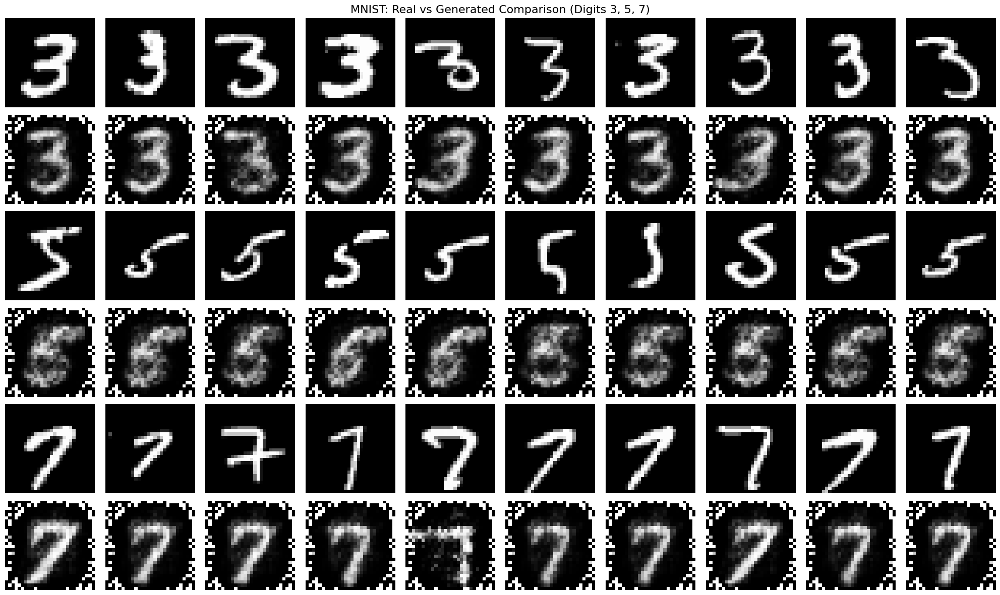

In [8]:
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# Settings
digits = [3, 5, 7]
num_samples = 10  # Number of real and fake samples per digit
save_dir = "./outputs/MNIST"

# Recreate Generator
G = Generator(z_dim, y_dim, img_dim).to(DEVICE)
G.load_state_dict(torch.load(f"{save_dir}/G.pth", map_location=DEVICE))
G.eval()

# One-hot encoding function
def make_one_hot(labels, num_classes):
    return torch.zeros(labels.size(0), num_classes, device=labels.device).scatter_(1, labels.unsqueeze(1), 1)

# Load Real MNIST Data
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1))  # Flatten to (784,)
])

mnist = datasets.MNIST(root="./data", train=True, download=True, transform=transform)

# Collect real images for each digit
real_imgs_by_digit = {}
for d in digits:
    imgs = []
    for img, label in mnist:
        if label == d:
            imgs.append(img.view(28, 28))
        if len(imgs) >= num_samples:
            break
    real_imgs_by_digit[d] = torch.stack(imgs)

# Generate fake images for each digit
fake_imgs_by_digit = {}
for d in digits:
    z = torch.randn(num_samples, z_dim, device=DEVICE)
    labels = torch.full((num_samples,), d, dtype=torch.long, device=DEVICE)
    one_hot_labels = make_one_hot(labels, y_dim)

    with torch.no_grad():
        fake_imgs = G(z, one_hot_labels).cpu().view(-1, 28, 28)
    fake_imgs_by_digit[d] = fake_imgs

# Plot: for each digit -> 2 rows (Real, Generated)
rows = 2 * len(digits)
fig, axes = plt.subplots(rows, num_samples, figsize=(2 * num_samples, 2 * rows))

for di, d in enumerate(digits):
    r_real = 2 * di
    r_fake = 2 * di + 1

    for i in range(num_samples):
        axes[r_real, i].imshow(real_imgs_by_digit[d][i], cmap="gray")
        axes[r_real, i].axis("off")
        if i == 0:
            axes[r_real, i].set_ylabel(f"Real {d}", fontsize=12)

    for i in range(num_samples):
        axes[r_fake, i].imshow(fake_imgs_by_digit[d][i], cmap="gray")
        axes[r_fake, i].axis("off")
        if i == 0:
            axes[r_fake, i].set_ylabel(f"Gen {d}", fontsize=12)

plt.suptitle("MNIST: Real vs Generated Comparison (Digits 3, 5, 7)", fontsize=16)
plt.tight_layout()
plt.show()

## MNIST Outputs During Training: Semantic Controllability Check

The figure above shows **real vs generated MNIST samples** for digits **3, 5, and 7**, visualized while training is in progress.

### Structure of the Visualization
- **Top row of each pair**: real MNIST samples corresponding to a fixed semantic label  
- **Bottom row of each pair**: images generated by the vision module under the *same label condition*  
- Each digit is evaluated independently to assess **semantic isolation and controllability**

### Observations
- The generator consistently produces digit shapes aligned with the requested label (3, 5, or 7), indicating that **semantic conditioning is respected**.
- Generated samples are visibly blurrier than real images, which is expected given:
  - the fully connected architecture,
  - the low spatial resolution (28×28),
  - and the early-stage nature of training.
- Despite reduced sharpness, **digit identity remains clear**, demonstrating that the model has learned class-level structure rather than memorizing individual samples.

### Robotics Interpretation
In a robotics context, this result confirms that:
- symbolic priors (labels) can reliably control visual outputs,
- the perception module can generate **class-consistent observations** under uncertainty,
- and the core conditioning mechanism is functioning correctly.

This MNIST experiment establishes a **baseline level of semantic controllability**, validating the perception pipeline before transitioning to higher-resolution, higher-entropy environments such as Oxford-102 and CUB-200.

# **Transition to Real-World Vision**

# **Oxford-102**

## Oxford-102 Configuration

This section defines the **system configuration** for extending label-conditioned robot vision from a low-entropy baseline (MNIST) to a **real-world, fine-grained visual dataset**.

The Oxford-102 Flowers dataset introduces challenges commonly encountered in robotic vision:
- high intra-class variability,
- inter-class visual similarity,
- class imbalance,
- and complex color and texture distributions.

This configuration simulates a **camera-based perception module** operating in a natural environment, where visual categories are more nuanced and less separable than synthetic or symbolic data.

Key configuration considerations:
- **Reduced batch size** to accommodate higher-resolution RGB imagery and increased model complexity.
- **Expanded semantic space (`y_dim = 102`)**, representing a richer set of object categories available to the vision system.
- **Fixed latent dimension** to maintain comparability with the MNIST baseline while isolating the effect of visual complexity.
- **Standardized image resolution (64×64 RGB)** to balance perceptual detail and computational feasibility.

This configuration sets the stage for evaluating how label-conditioned robot vision scales when exposed to **realistic visual diversity**, prior to further extension to even higher-entropy environments.

In [9]:
dataset_name = "Oxford102"

# Hyperparameters
batch_size  = 64            # Flowers are heavier than MNIST, so batch smaller
z_dim       = 100           # Latent vector dimension
y_dim       = 102           # 102 flower categories
img_size    = 64            # Resize all to 64x64
img_channels= 3             # RGB images
img_dim     = img_size * img_size * img_channels
lr          = 0.0002
epochs      = 200           # Same as MNIST

save_dir = f"./outputs/{dataset_name}"
os.makedirs(save_dir, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


## Oxford-102 Dataset Acquisition and Ground-Truth Setup

This cell prepares the **real-world visual dataset** used to evaluate label-conditioned robot vision beyond synthetic baselines.

This step corresponds to **sensor data provisioning and annotation loading**, where:
- raw visual observations (RGB images) are acquired,
- semantic ground-truth labels are retrieved separately,
- and both are organized into a structured dataset for downstream perception modeling.

Key aspects of this setup:
- The Oxford-102 Flowers dataset provides **high visual diversity** in color, texture, and shape, representative of natural environments encountered by robotic vision systems.
- Images and labels are downloaded independently, reflecting realistic scenarios where **sensor data and annotations are decoupled**.
- Labels stored in MATLAB format (`.mat`) are later parsed to construct explicit semantic priors for label-conditioned vision.

This step ensures a reproducible and well-defined dataset foundation before preprocessing, model training, and evaluation.

In [10]:
import os
import urllib.request
import tarfile
import scipy.io

# Create target directory
oxford102_root = "./data/Oxford102"
os.makedirs(oxford102_root, exist_ok=True)

images_url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz"
labels_url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/imagelabels.mat"

# Target paths
images_tar_path = os.path.join(oxford102_root, "102flowers.tgz")
labels_mat_path = os.path.join(oxford102_root, "imagelabels.mat")

# Download images archive if not already downloaded
if not os.path.exists(images_tar_path):
    print("Downloading 102flowers.tgz...")
    urllib.request.urlretrieve(images_url, images_tar_path)
    print("Downloaded images archive!")

# Extract images if not already extracted
jpg_folder = os.path.join(oxford102_root, "jpg")
if not os.path.exists(jpg_folder):
    print("Extracting images...")
    with tarfile.open(images_tar_path, "r:gz") as tar:
        tar.extractall(path=oxford102_root)
    print("Extraction complete!")

# Download labels if not already downloaded
if not os.path.exists(labels_mat_path):
    print("Downloading imagelabels.mat...")
    urllib.request.urlretrieve(labels_url, labels_mat_path)
    print("Downloaded labels file!")

print("Oxford-102 dataset downloaded.")

Downloaded images archive!
Extracting images...
Extraction complete!
Downloaded labels file!
Oxford-102 dataset downloaded.


## Oxford-102 Dataset Interface and Vision Preprocessing

This section defines a **custom dataset interface** for integrating the Oxford-102 Flowers dataset into the label-conditioned robot vision pipeline.

This step corresponds to building a **vision sensor abstraction**, where raw RGB observations and semantic annotations are transformed into a standardized format consumable by the perception module.

Key design choices:
- **Image resizing** to a fixed resolution (64×64) simulates a constrained camera sensor input.
- **Normalization to [-1, 1]** ensures stable learning dynamics for generative vision models.
- **Explicit label alignment** converts dataset-provided annotations into zero-indexed semantic classes compatible with robot vision conditioning.
- A custom `Dataset` class enforces a clean separation between **data storage**, **preprocessing**, and **model consumption**, mirroring modular robotics software design.

The resulting DataLoader provides shuffled, batch-aligned image–label pairs, enabling scalable training and evaluation of label-conditioned vision under realistic visual diversity.

In [11]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import scipy.io

# Define transformations
transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

# Paths
oxford102_root = "./data/Oxford102"
image_dir = os.path.join(oxford102_root, "jpg")
labels_mat_path = os.path.join(oxford102_root, "imagelabels.mat")

# Custom Dataset Class
class Oxford102Dataset(Dataset):
    def __init__(self, image_dir, labels_mat_path, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        
        # Load labels
        labels_data = scipy.io.loadmat(labels_mat_path)
        self.labels = labels_data["labels"][0]  # (8189,)
        
        # Load image file names
        self.image_files = sorted(os.listdir(image_dir))
        
        assert len(self.labels) == len(self.image_files), "Mismatch between number of labels and images!"
        
    def __len__(self):
        return len(self.image_files)
    
    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, self.image_files[idx])
        image = Image.open(img_path).convert("RGB")
        label = self.labels[idx] - 1  # MATLAB indexing starts from 1 and not 0
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

# Instantiate dataset and dataloader
oxford_dataset = Oxford102Dataset(
    image_dir=image_dir,
    labels_mat_path=labels_mat_path,
    transform=transform
)

oxford_loader = DataLoader(
    oxford_dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,
    num_workers=0,
    pin_memory=True,
)

print(f"Oxford-102 dataset ready: {len(oxford_dataset)} images across {y_dim} classes.")

Oxford-102 dataset ready: 8189 images across 102 classes.


## Oxford-102 Vision Module: Convolutional Label-Conditioned Architecture (64×64)

This cell defines the **64×64 RGB** label-conditioned generator and discriminator used for the Oxford-102 experiment.

In a robotics setting, moving from MNIST to Oxford-102 is a shift from a symbolic sanity check to a **camera-like perception regime**, where spatial structure (edges, textures, shapes) matters. Fully connected models blur spatial locality, so this stage uses a **convolutional (DCGAN-style) vision backbone** to preserve and refine spatial features during generation and verification.

---

### Conditioning Mechanism: Spatial Semantic Injection

Oxford-102 uses **102 classes**, so the semantic prior $y$ is high-dimensional. Instead of conditioning only at the input, this architecture injects semantics at **multiple spatial scales**:

- `expand_y(y, h, w)` tiles one-hot labels across the spatial grid
- The tiled label map is concatenated with feature maps at each conv stage

This mirrors robotics practice where **semantic context influences perception at different feature levels** (coarse shapes early, fine details later).

---

### Generator64: Semantic-to-Image Synthesis (Camera Observation Model)

The generator produces an RGB observation:

$$
G(z, y) \rightarrow x \in \mathbb{R}^{3 \times 64 \times 64}
$$

Design highlights:
- Latent $z$ and label $y$ are fused and projected into a compact spatial seed (4×4×512)
- A stack of transposed convolutions upsamples to 64×64
- Label maps are injected at every upsampling stage to enforce **semantic controllability**
- Final `tanh` output matches the normalized image range \([-1, 1]\)

Interpretation: a **label-conditioned camera simulator** producing class-aligned visual hypotheses.

---

### Discriminator64: Conditional Realism + Consistency Verifier

The discriminator evaluates whether an image is both:
1) **visually plausible** (looks like a real flower image at this resolution), and  
2) **consistent with the provided semantic prior** (label $y$)

$$
D(x, y) \rightarrow \text{logit}
$$

Design highlights:
- The label map is concatenated at every downsampling stage
- Convolutional hierarchy extracts progressively higher-level visual structure
- Final output is a single logit (intended for **BCEWithLogitsLoss**)

Interpretation: a **semantic consistency verifier**—akin to checking whether a perception hypothesis matches a claimed class.

---

### Why This Matters (Robotics Lens)

This architecture is the first “real” robot-vision version of the project:
- it preserves spatial structure,
- scales to 100+ semantic classes,
- and exposes robotics-relevant failure modes (class entanglement, background bias, limited detail at fixed resolution).

In [12]:
import torch.nn as nn
import torch

# Utility function to expand one-hot labels spatially
def expand_y(y, h, w):
    """Expand y: (B,C) -> (B,C,h,w) by spatial tiling."""
    return y.view(y.size(0), y.size(1), 1, 1).expand(-1, -1, h, w)

# Generator for 64x64 images
class Generator64(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(z_dim + y_dim, 4 * 4 * 512),
            nn.BatchNorm1d(4 * 4 * 512),
            nn.ReLU(True)
        )
        self.conv_blocks = nn.ModuleList([
            nn.ConvTranspose2d(512 + y_dim, 256, 4, 2, 1, bias=False),  # 8x8
            nn.ConvTranspose2d(256 + y_dim, 128, 4, 2, 1, bias=False),  # 16x16
            nn.ConvTranspose2d(128 + y_dim, 64, 4, 2, 1, bias=False),   # 32x32
            nn.ConvTranspose2d(64 + y_dim, 3, 4, 2, 1, bias=False)      # 64x64
        ])
        self.bns = nn.ModuleList([
            nn.BatchNorm2d(256),
            nn.BatchNorm2d(128),
            nn.BatchNorm2d(64)
        ])

    def forward(self, z, y):  # z: (B, 100), y: (B, 102)
        x = torch.cat([z, y], dim=1)  # (B, 202)
        x = self.fc(x).view(-1, 512, 4, 4)  # (B, 512, 4, 4)

        for i, conv in enumerate(self.conv_blocks):
            h, w = x.shape[2], x.shape[3]
            y_exp = expand_y(y, h, w)
            x = torch.cat([x, y_exp], dim=1)
            x = conv(x)
            if i < 3:
                x = self.bns[i](x)
                x = nn.ReLU(True)(x)
            else:
                x = torch.tanh(x)
        return x

# Discriminator for 64x64 images
class Discriminator64(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_blocks = nn.ModuleList([
            nn.Conv2d(3 + y_dim, 64, 4, 2, 1, bias=True),   # 32x32
            nn.Conv2d(64 + y_dim, 128, 4, 2, 1, bias=True), # 16x16
            nn.Conv2d(128 + y_dim, 256, 4, 2, 1, bias=True),# 8x8
            nn.Conv2d(256 + y_dim, 512, 4, 2, 1, bias=True) # 4x4
        ])
        self.fc = nn.Linear(4 * 4 * 512, 1)  # Final linear layer for logits

    def forward(self, x, y):  # x: (B, 3, 64, 64), y: (B, 102)
        for conv in self.conv_blocks:
            h, w = x.shape[2], x.shape[3]
            y_exp = expand_y(y, h, w)
            x = torch.cat([x, y_exp], dim=1)
            x = conv(x)
            x = nn.LeakyReLU(0.2, inplace=True)(x)
        
        x = x.view(x.size(0), -1)  # Flatten
        x = self.fc(x)             # Logits (use BCEWithLogitsLoss later)
        return x

## Optimization Setup and Learning Objective (Oxford-102)

This cell initializes the **learning components** for the Oxford-102 label-conditioned robot vision module.

- The **Generator** and **Discriminator** together form a trainable perception subsystem.
- **Adam optimization** is used to ensure stable convergence under adversarial learning dynamics.
- **Binary Cross-Entropy with Logits** provides a numerically stable objective for evaluating visual realism and semantic consistency jointly.

This setup defines the **learning objective and control parameters** governing how the vision module adapts to complex, real-world visual data.

In [13]:
import torch.optim as optim
import torch.nn as nn

# Initialize models
G = Generator64().to(DEVICE)
D = Discriminator64().to(DEVICE)

# Optimizers
G_optimizer = optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
D_optimizer = optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))

# Loss Function
criterion = nn.BCEWithLogitsLoss()

print("Optimizers and Loss function = READY")

Optimizers and Loss function = READY


## Semantic Label Encoding Utility

This utility converts discrete class indices into **one-hot semantic vectors**, which serve as explicit conditioning signals for the robot vision module.

In a robotics context, this step formalizes symbolic category information into a machine-consumable representation, enabling controlled interaction between **semantic priors** and **visual generation**.

In [14]:
def make_one_hot(labels, num_classes):
    """
    Converts integer labels into one-hot encoded vectors.
    labels: (batch_size,) --> returns (batch_size, num_classes)
    """
    return torch.zeros(labels.size(0), num_classes, device=labels.device).scatter_(1, labels.unsqueeze(1), 1)

## Visual Monitoring Utility for Perception Outputs

This helper function saves **gridded visual outputs** produced by the label-conditioned robot vision module at different training stages.

This serves as a **qualitative monitoring tool** to inspect:
- semantic controllability across labels,
- visual consistency within each class,
- and the progression of perceptual structure over training epochs.

Such visual checkpoints are essential for diagnosing perception failure modes that may not be immediately visible through scalar metrics alone.

In [15]:
import matplotlib.pyplot as plt

def save_image_grid(images, labels, epoch, save_dir, nrow=8):
    """
    Save a grid of generated images grouped by their labels.
    """
    images = images.detach().cpu()
    images = (images + 1) / 2  # Denormalize from [-1,1] to [0,1]
    
    batch_size = images.size(0)
    fig, axes = plt.subplots(nrows=(batch_size // nrow) + 1, ncols=nrow, figsize=(nrow * 2, (batch_size // nrow) * 2))
    axes = axes.flatten()

    for img, ax in zip(images, axes):
        img = img.permute(1, 2, 0)  # (C,H,W) --> (H,W,C)
        ax.imshow(img)
        ax.axis('off')
    
    for ax in axes[batch_size:]:
        ax.axis('off')
        
    plt.tight_layout()
    os.makedirs(save_dir, exist_ok=True)
    plt.savefig(os.path.join(save_dir, f"epoch_{epoch:03d}.png"))
    plt.close()

## Offline Training Loop: Oxford-102 Label-Conditioned Robot Vision

This section implements the **offline training procedure** for the Oxford-102 label-conditioned robot vision module.

This loop corresponds to training a **camera-based perception subsystem** under explicit semantic constraints. The system learns to associate **high-cardinality semantic labels (102 classes)** with realistic visual observations in a natural environment.

Key characteristics of this training process:
- The **Discriminator** evaluates both visual realism and semantic consistency between images and labels.
- The **Generator** learns to synthesize RGB observations that satisfy the provided semantic prior.
- Training proceeds in alternating optimization steps, reflecting adversarial learning dynamics.
- Fixed latent vectors and labels are used to generate **consistent visual checkpoints**, enabling longitudinal inspection of perceptual evolution.

Periodic visualization and saving of generated samples support:
- qualitative assessment of semantic controllability,
- detection of class entanglement and background bias,
- and analysis of convergence behavior beyond scalar loss values.

At the end of training, model parameters and loss histories are saved for reproducibility, post-hoc analysis, and comparison across datasets.

Epoch [1/200]  D_loss: 1.6744  G_loss: 0.9149


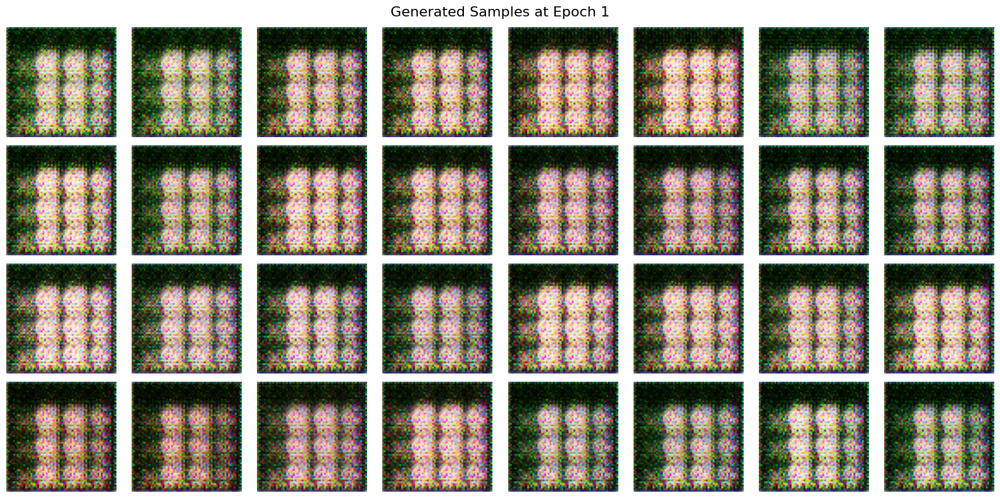

Epoch [2/200]  D_loss: 1.4074  G_loss: 0.8049


Epoch [3/200]  D_loss: 1.3169  G_loss: 0.7801


Epoch [4/200]  D_loss: 1.3291  G_loss: 0.7430


Epoch [5/200]  D_loss: 1.3794  G_loss: 0.7952


Epoch [6/200]  D_loss: 1.3348  G_loss: 0.7731


Epoch [7/200]  D_loss: 1.3382  G_loss: 0.7471


... (29 outputs left out)

Epoch [37/200]  D_loss: 1.1043  G_loss: 1.0880


Epoch [38/200]  D_loss: 1.0155  G_loss: 1.4831


Epoch [39/200]  D_loss: 1.1812  G_loss: 1.2089


Epoch [40/200]  D_loss: 1.0785  G_loss: 1.2992


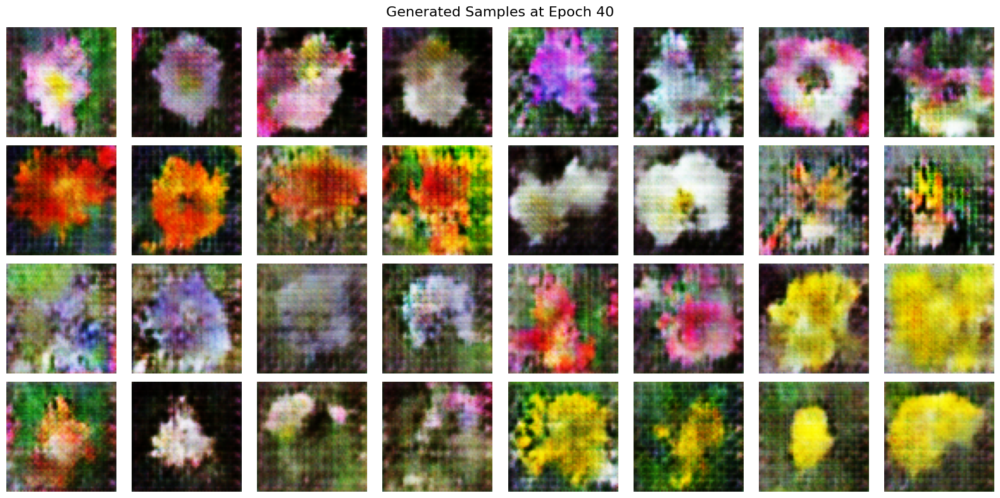

Epoch [41/200]  D_loss: 1.0904  G_loss: 1.4940


Epoch [42/200]  D_loss: 1.1243  G_loss: 1.5640


Epoch [43/200]  D_loss: 0.8749  G_loss: 1.3601


Epoch [44/200]  D_loss: 0.8583  G_loss: 1.5626


Epoch [45/200]  D_loss: 0.7941  G_loss: 1.5629


Epoch [46/200]  D_loss: 0.8972  G_loss: 1.4804


... (30 outputs left out)

Epoch [77/200]  D_loss: 0.5449  G_loss: 2.6765


Epoch [78/200]  D_loss: 0.5998  G_loss: 2.9468


Epoch [79/200]  D_loss: 0.4639  G_loss: 2.9669


Epoch [80/200]  D_loss: 0.4382  G_loss: 2.9749


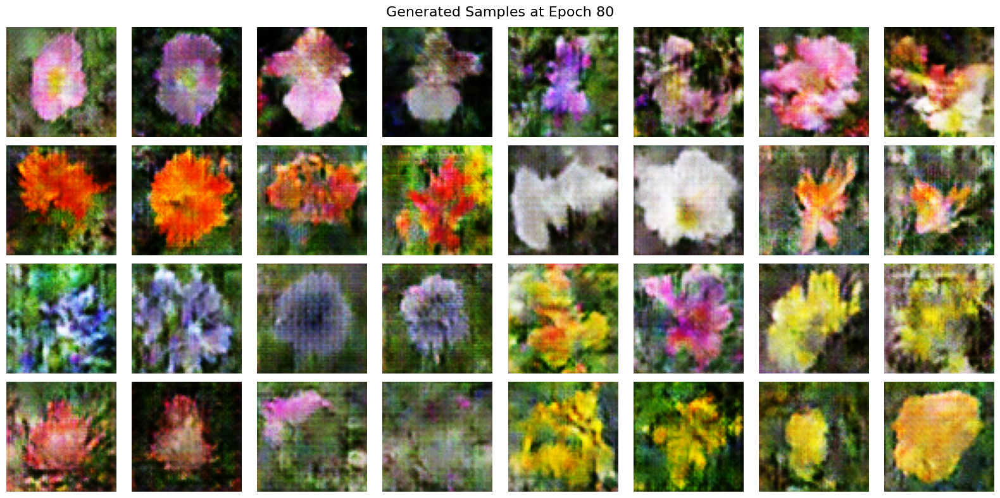

Epoch [81/200]  D_loss: 0.6957  G_loss: 2.7150


Epoch [82/200]  D_loss: 0.3303  G_loss: 3.3140


Epoch [83/200]  D_loss: 0.4186  G_loss: 3.6647


Epoch [84/200]  D_loss: 0.4667  G_loss: 4.2158


Epoch [85/200]  D_loss: 0.4554  G_loss: 3.4569


Epoch [86/200]  D_loss: 0.5253  G_loss: 3.0498


... (30 outputs left out)

Epoch [117/200]  D_loss: 0.3421  G_loss: 4.4607


Epoch [118/200]  D_loss: 0.2699  G_loss: 4.9527


Epoch [119/200]  D_loss: 0.2461  G_loss: 5.0060


Epoch [120/200]  D_loss: 0.3215  G_loss: 4.9775


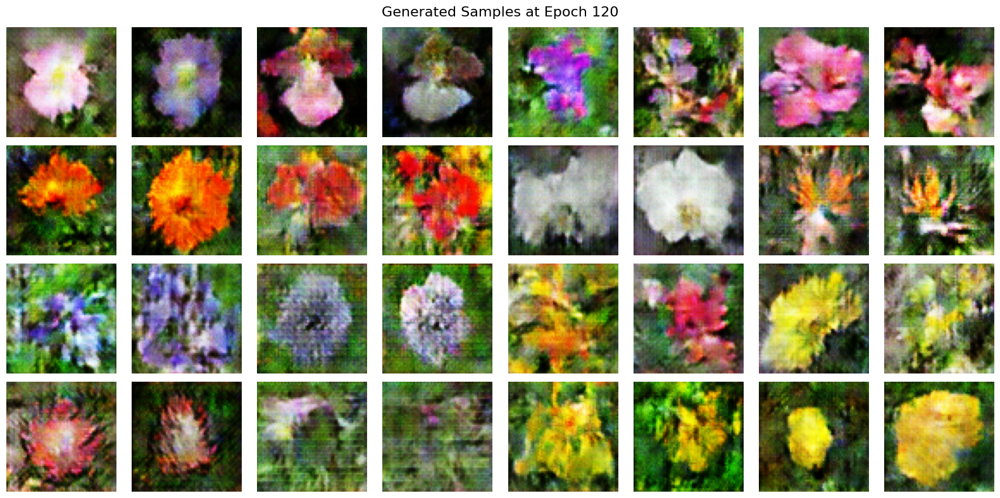

Epoch [121/200]  D_loss: 0.2650  G_loss: 5.0381


Epoch [122/200]  D_loss: 0.2707  G_loss: 5.4060


Epoch [123/200]  D_loss: 0.1408  G_loss: 5.8613


Epoch [124/200]  D_loss: 0.3450  G_loss: 5.0752


Epoch [125/200]  D_loss: 0.3134  G_loss: 5.4500


Epoch [126/200]  D_loss: 0.5105  G_loss: 4.6008


... (30 outputs left out)

Epoch [157/200]  D_loss: 0.1712  G_loss: 5.9265


Epoch [158/200]  D_loss: 0.2423  G_loss: 6.0525


Epoch [159/200]  D_loss: 0.0926  G_loss: 6.2961


Epoch [160/200]  D_loss: 0.1030  G_loss: 6.2695


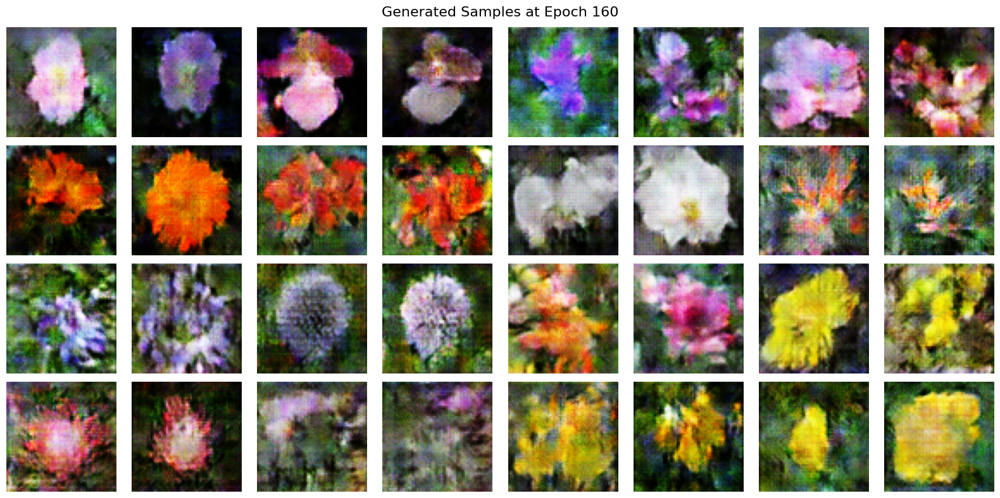

Epoch [161/200]  D_loss: 0.1588  G_loss: 8.1462


Epoch [162/200]  D_loss: 0.2745  G_loss: 6.5359


Epoch [163/200]  D_loss: 0.0738  G_loss: 6.3661


Epoch [164/200]  D_loss: 0.2742  G_loss: 6.7502


Epoch [165/200]  D_loss: 0.0843  G_loss: 6.3409


Epoch [166/200]  D_loss: 0.2413  G_loss: 6.5050


... (30 outputs left out)

Epoch [197/200]  D_loss: 0.1106  G_loss: 7.6806


Epoch [198/200]  D_loss: 0.1523  G_loss: 7.6056


Epoch [199/200]  D_loss: 0.1078  G_loss: 7.0692


Epoch [200/200]  D_loss: 0.1733  G_loss: 7.2183


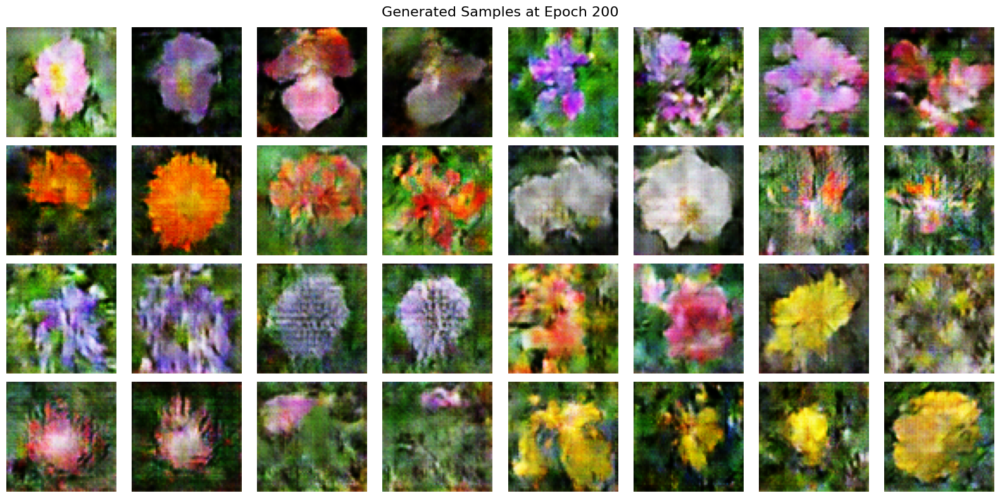

Training done and all models and losses saved.


In [16]:
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

# Fixed noise and labels for consistent evaluation
fixed_z = torch.randn(y_dim * 2, z_dim, device=DEVICE)
fixed_labels = torch.arange(y_dim, device=DEVICE).repeat_interleave(2)
fixed_labels_onehot = make_one_hot(fixed_labels, y_dim)

D_losses = []
G_losses = []

for epoch in range(1, epochs + 1):
    loop = tqdm(oxford_loader, leave=False, desc=f"Epoch {epoch}/{epochs}")
    for real_imgs, labels in loop:
        real_imgs, labels = real_imgs.to(DEVICE), labels.to(DEVICE)
        bsize = real_imgs.size(0)
        
        real_targets = torch.ones(bsize, 1, device=DEVICE)
        fake_targets = torch.zeros(bsize, 1, device=DEVICE)
        
        labels_onehot = make_one_hot(labels.long(), y_dim)  

        # Train Discriminator
        D_optimizer.zero_grad()
        
        D_real = D(real_imgs, labels_onehot)
        D_loss_real = criterion(D_real, real_targets)
        
        z = torch.randn(bsize, z_dim, device=DEVICE)
        fake_imgs = G(z, labels_onehot)
        D_fake = D(fake_imgs.detach(), labels_onehot)
        D_loss_fake = criterion(D_fake, fake_targets)
        
        D_loss = D_loss_real + D_loss_fake
        D_loss.backward()
        D_optimizer.step()
        
        # Train Generator
        G_optimizer.zero_grad()
        
        z = torch.randn(bsize, z_dim, device=DEVICE)
        fake_imgs = G(z, labels_onehot)
        D_fake = D(fake_imgs, labels_onehot)
        G_loss = criterion(D_fake, real_targets)
        
        G_loss.backward()
        G_optimizer.step()
        
        D_losses.append(D_loss.item())
        G_losses.append(G_loss.item())
        
    
    print(f"Epoch [{epoch}/{epochs}]  D_loss: {D_loss.item():.4f}  G_loss: {G_loss.item():.4f}")
    
    # Save and Show Fake Samples every 40 epochs
    if epoch % 40 == 0 or epoch == 1:
        with torch.no_grad():
            fake_imgs_fixed = G(fixed_z, fixed_labels_onehot)
        
        # Save to file
        save_image_grid(fake_imgs_fixed, fixed_labels, epoch, save_dir)
        
        # Show in notebook
        fig, axes = plt.subplots(4, 8, figsize=(16, 8))
        axes = axes.flatten()
        fake_imgs_fixed = fake_imgs_fixed.detach().cpu()
        fake_imgs_fixed = (fake_imgs_fixed + 1) / 2  # denormalize

        for img, ax in zip(fake_imgs_fixed, axes):
            img = img.permute(1, 2, 0)
            ax.imshow(img)
            ax.axis('off')

        for ax in axes[len(fake_imgs_fixed):]:
            ax.axis('off')

        plt.suptitle(f"Generated Samples at Epoch {epoch}", fontsize=16)
        plt.tight_layout()
        plt.show()


np.save(os.path.join(save_dir, "D_losses.npy"), np.array(D_losses))
np.save(os.path.join(save_dir, "G_losses.npy"), np.array(G_losses))
torch.save(G.state_dict(), os.path.join(save_dir, "generator.pth"))
torch.save(D.state_dict(), os.path.join(save_dir, "discriminator.pth"))

print("Training done and all models and losses saved.")

## Semantic Visualization: Class-Wise Vision Outputs (Oxford-102)

This section performs a **class-wise qualitative evaluation** of the trained label-conditioned robot vision module on the Oxford-102 dataset.

This visualization tests whether the vision system can:
- generate **distinct visual hypotheses** for each semantic class,
- maintain **semantic alignment** between labels and visual structure,
- and exhibit reasonable inter-class separation across a large category space.

One synthetic image is generated per class using fixed latent vectors and explicit semantic conditioning. The generated outputs are displayed alongside their corresponding class names to enable **human-interpretable inspection** of the vision module’s behavior.

This analysis supports:
- verification of semantic controllability at scale (102 classes),
- identification of visually confused or entangled categories,
- and assessment of how well the perception module internalizes class-level structure in a natural image domain.

Such qualitative grounding is critical in robotics, where perception outputs must remain interpretable and diagnosable before downstream use in autonomy pipelines.

C:\Users\aymisxx\AppData\Local\Temp\ipykernel_10568\595977269.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  G.load_state_dict(torch.load(os.path.join(save_dir, "genera

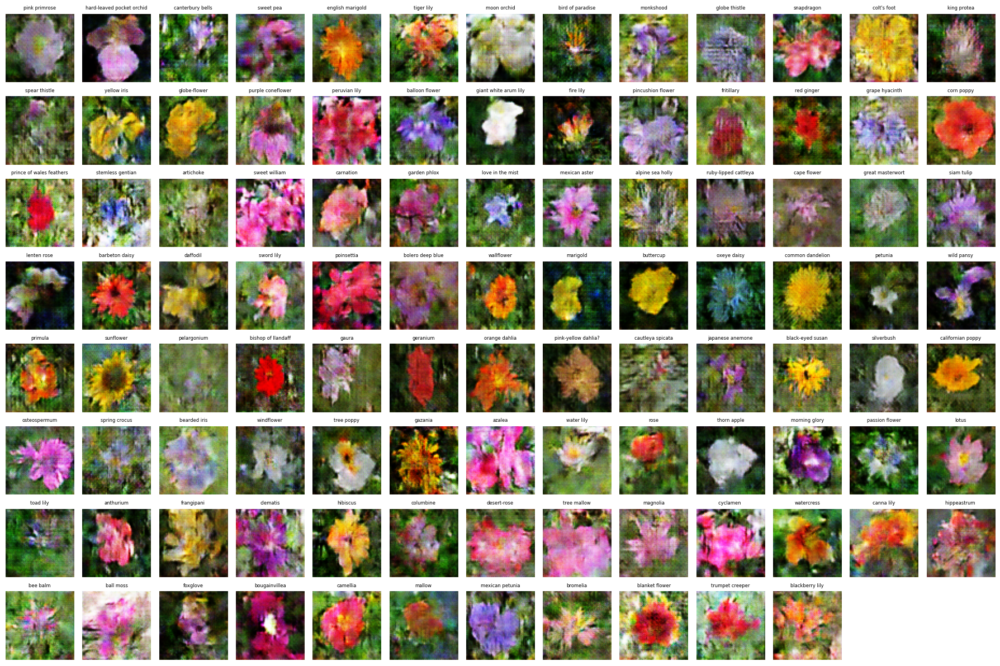

In [17]:
import torch
import matplotlib.pyplot as plt
import os

# Load trained Generator
G = Generator64().to(DEVICE)
G.load_state_dict(torch.load(os.path.join(save_dir, "generator.pth"), map_location=DEVICE))
G.eval()  # Set to evaluation mode

# Prepare Correct Class Names (Oxford-102 flowers)
class_names = [
    'pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold',
    'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle', 'snapdragon',
    "colt's foot", 'king protea', 'spear thistle', 'yellow iris', 'globe-flower', 'purple coneflower',
    'peruvian lily', 'balloon flower', 'giant white arum lily', 'fire lily', 'pincushion flower', 'fritillary',
    'red ginger', 'grape hyacinth', 'corn poppy', 'prince of wales feathers', 'stemless gentian', 'artichoke',
    'sweet william', 'carnation', 'garden phlox', 'love in the mist', 'mexican aster', 'alpine sea holly',
    'ruby-lipped cattleya', 'cape flower', 'great masterwort', 'siam tulip', 'lenten rose', 'barbeton daisy',
    'daffodil', 'sword lily', 'poinsettia', 'bolero deep blue', 'wallflower', 'marigold', 'buttercup',
    'oxeye daisy', 'common dandelion', 'petunia', 'wild pansy', 'primula', 'sunflower', 'pelargonium',
    'bishop of llandaff', 'gaura', 'geranium', 'orange dahlia', 'pink-yellow dahlia?', 'cautleya spicata',
    'japanese anemone', 'black-eyed susan', 'silverbush', 'californian poppy', 'osteospermum', 'spring crocus',
    'bearded iris', 'windflower', 'tree poppy', 'gazania', 'azalea', 'water lily', 'rose', 'thorn apple',
    'morning glory', 'passion flower', 'lotus', 'toad lily', 'anthurium', 'frangipani', 'clematis', 'hibiscus',
    'columbine', 'desert-rose', 'tree mallow', 'magnolia', 'cyclamen ', 'watercress', 'canna lily', 'hippeastrum ',
    'bee balm', 'ball moss', 'foxglove', 'bougainvillea', 'camellia', 'mallow', 'mexican petunia', 'bromelia',
    'blanket flower', 'trumpet creeper', 'blackberry lily'
]

# Generate samples
fixed_z = torch.randn(y_dim, z_dim, device=DEVICE)  # 1 sample per class
fixed_labels = torch.arange(y_dim, device=DEVICE)
fixed_labels_onehot = make_one_hot(fixed_labels, y_dim)

with torch.no_grad():
    fake_imgs = G(fixed_z, fixed_labels_onehot)

# Show and map flowers
fig, axes = plt.subplots(8, 13, figsize=(18, 12))
axes = axes.flatten()

fake_imgs = (fake_imgs + 1) / 2  # Denormalize from [-1,1] to [0,1]

for idx, (img, ax) in enumerate(zip(fake_imgs, axes)):
    img = img.detach().cpu().permute(1, 2, 0)
    ax.imshow(img)
    if idx < len(class_names):
        ax.set_title(f"{class_names[idx]}", fontsize=6)
    ax.axis('off')

# Hide extra axes if any
for ax in axes[len(fake_imgs):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

## Oxford-102 Flower Classes: Index → Semantic Label Mapping

Each class index represents a distinct semantic category used for label-conditioned robot vision.

1. Pink primrose
2. Hard-leaved pocket orchid
3. Canterbury bells
4. Sweet pea
5. English marigold
6. Tiger lily
7. Moon orchid
8. Bird of paradise
9. Monkshood
10. Globe thistle
11. Snapdragon
12. Colt’s foot
13. King protea
14. Spear thistle
15. Yellow iris
16. Globe-flower
17. Purple coneflower
18. Peruvian lily
19. Ball moss
20. Mexican petunia
21. Bromelia
22. Blanket flower
23. Trumpet creeper
24. Black-eyed susan
25. Pontederia
26. Bolero deep blue
27. Bougainvillea
28. Camellia
29. Mallow
30. Mexican aster
31. Alpine sea holly
32. Ruby-lipped cattleya
33. Cape flower
34. Great masterwort
35. Siam tulip
36. Lenten rose
37. Barbeton daisy
38. Daffodil
39. Sword lily
40. Poinsettia
41. Gaura
42. Geranium
43. Orange dahlia
44. Pink-yellow dahlia
45. Cautleya spicata
46. Japanese anemone
47. Blackberry lily
48. Tree poppy
49. Gazania
50. Azalea
51. Water lily
52. Rose
53. Thorn apple
54. Morning glory
55. Passion flower
56. Lotus
57. Toad lily
58. Anthurium
59. Frangipani
60. Clematis
61. Hibiscus
62. Columbine
63. Desert-rose
64. Tree mallow
65. Magnolia
66. Cyclamen
67. Watercress
68. Canna lily
69. Hippeastrum
70. Bee balm
71. Balloon flower
72. Oxeye daisy
73. Fire lily
74. Pincushion flower
75. Fritillary
76. Red ginger
77. Grape hyacinth
78. Corn poppy
79. Prince of wales feathers
80. Stemless gentian
81. Artichoke
82. Sweet william
83. Carnation
84. Garden phlox
85. Love in the mist
86. Mexican sunflower
87. Wild pansy
88. Primula
89. Sunflower
90. Pelargonium
91. Bishop of llandaff
92. Gaillardia
93. Buttercup
94. Oxlip
95. Tiger flower
96. Rose mallow
97. Snapdragon
98. Columbine
99. Colt’s foot
100. King protea
101. Spear thistle
102. Globe thistle

In [18]:
import os
import torch
import random
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import scipy.io

# Paths
real_image_folder = os.path.join(oxford102_root, "jpg")
labels_mat_path = os.path.join(oxford102_root, "imagelabels.mat")

class_names = [
    'pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold',
    'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle', 'snapdragon',
    "colt's foot", 'king protea', 'spear thistle', 'yellow iris', 'globe-flower', 'purple coneflower',
    'peruvian lily', 'balloon flower', 'giant white arum lily', 'fire lily', 'pincushion flower', 'fritillary',
    'red ginger', 'grape hyacinth', 'corn poppy', 'prince of wales feathers', 'stemless gentian', 'artichoke',
    'sweet william', 'carnation', 'garden phlox', 'love in the mist', 'mexican aster', 'alpine sea holly',
    'ruby-lipped cattleya', 'cape flower', 'great masterwort', 'siam tulip', 'lenten rose', 'barbeton daisy',
    'daffodil', 'sword lily', 'poinsettia', 'bolero deep blue', 'wallflower', 'marigold', 'buttercup',
    'oxeye daisy', 'common dandelion', 'petunia', 'wild pansy', 'primula', 'sunflower', 'pelargonium',
    'bishop of llandaff', 'gaura', 'geranium', 'orange dahlia', 'pink-yellow dahlia?', 'cautleya spicata',
    'japanese anemone', 'black-eyed susan', 'silverbush', 'californian poppy', 'osteospermum', 'spring crocus',
    'bearded iris', 'windflower', 'tree poppy', 'gazania', 'azalea', 'water lily', 'rose', 'thorn apple',
    'morning glory', 'passion flower', 'lotus', 'toad lily', 'anthurium', 'frangipani', 'clematis', 'hibiscus',
    'columbine', 'desert-rose', 'tree mallow', 'magnolia', 'cyclamen ', 'watercress', 'canna lily', 'hippeastrum ',
    'bee balm', 'ball moss', 'foxglove', 'bougainvillea', 'camellia', 'mallow', 'mexican petunia', 'bromelia',
    'blanket flower', 'trumpet creeper', 'blackberry lily'
]

## Class-Specific Grounding: Real vs Generated Comparisons

This section performs **targeted semantic grounding checks** for selected flower classes in the Oxford-102 dataset.

This evaluation answers a critical question:
> *Given an explicit semantic prior, can the vision module generate a plausible visual observation consistent with real sensor data?*

For a small set of representative classes (Corn Poppy, English Marigold, Snapdragon), we:
- retrieve a **real image** from the dataset corresponding to the target class,
- generate a **synthetic image** using the trained label-conditioned generator,
- and visualize both side-by-side for direct comparison.

This class-specific analysis enables:
- fine-grained inspection of semantic alignment,
- identification of intra-class variability and background bias,
- and qualitative validation of label-conditioned robot vision behavior beyond aggregate metrics.

Selected Flower: corn poppy (Label 25)


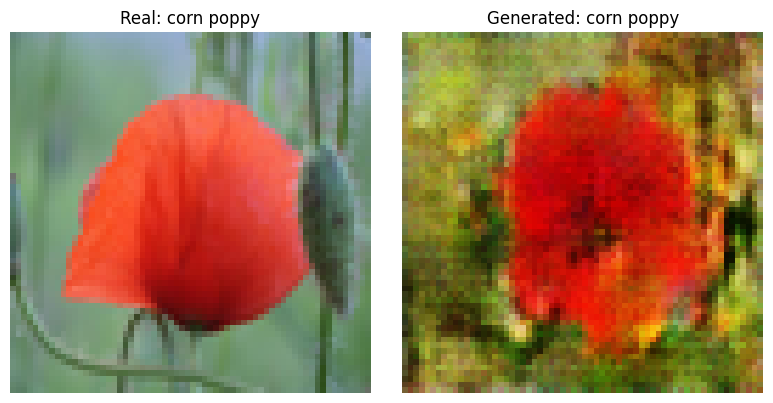

Selected Flower: english marigold (Label 4)


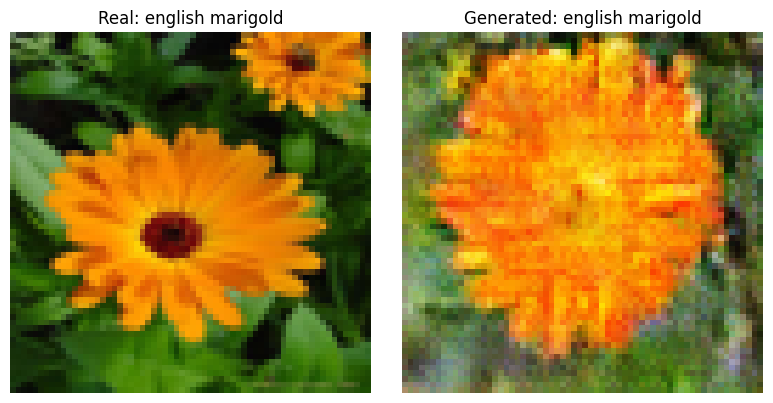

Selected Flower: snapdragon (Label 10)


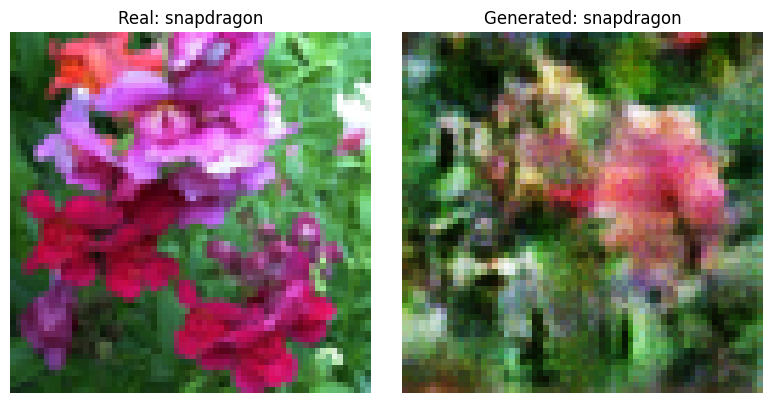

In [22]:
import os
import random
import torch
import matplotlib.pyplot as plt
from PIL import Image
import scipy.io

# Target flower classes for inspection
selected_flower_names = ["corn poppy", "english marigold", "snapdragon"]

# Load labels once
labels_data = scipy.io.loadmat(labels_mat_path)
real_labels = labels_data["labels"][0] - 1  # MATLAB labels are 1-indexed

image_files = sorted(os.listdir(real_image_folder))

# Loop over selected classes
for selected_flower_name in selected_flower_names:
    selected_label = class_names.index(selected_flower_name)
    print(f"Selected Flower: {selected_flower_name} (Label {selected_label})")

    # Find matching real images
    matching_indices = [i for i, lbl in enumerate(real_labels) if lbl == selected_label]
    real_idx = random.choice(matching_indices)
    real_img_path = os.path.join(real_image_folder, image_files[real_idx])

    # Load and preprocess real image
    real_img = Image.open(real_img_path).convert("RGB")
    real_img = real_img.resize((img_size, img_size))

    # Generate synthetic image
    z = torch.randn(1, z_dim, device=DEVICE)
    label_tensor = torch.tensor([selected_label], device=DEVICE)
    label_onehot = make_one_hot(label_tensor, y_dim)

    with torch.no_grad():
        fake_img = G(z, label_onehot)

    fake_img = (fake_img + 1) / 2  # Denormalize
    fake_img = fake_img.squeeze(0).permute(1, 2, 0).cpu().numpy()

    # Side-by-side visualization
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(real_img)
    axes[0].set_title(f"Real: {selected_flower_name}")
    axes[0].axis("off")

    axes[1].imshow(fake_img)
    axes[1].set_title(f"Generated: {selected_flower_name}")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

## Class-Specific Grounding Results: Real vs Generated Comparisons

The figure above presents **side-by-side comparisons** between real dataset images and corresponding images generated by the label-conditioned robot vision module for three representative classes: **Corn Poppy**, **English Marigold**, and **Snapdragon**.

This visualization evaluates **semantic grounding under explicit class conditioning** rather than photorealism alone.

### Observations

- **Semantic Color and Structure Preservation**  
  For all three classes, the generated images capture dominant **class-specific color distributions** (e.g., red for corn poppy, yellow–orange for marigold, pink–purple for snapdragon), indicating that the generator has internalized coarse semantic cues associated with each label.

- **Loss of Fine-Grained Detail**  
  Compared to real images, generated samples exhibit blurred edges and reduced structural clarity. This is expected given:
  - the fixed low resolution (64×64),
  - limited model capacity,
  - and the high intra-class variability of natural flower images.

- **Background Entanglement**  
  Generated images show noticeable blending between foreground and background textures, reflecting a common failure mode in conditional generative vision systems when trained on complex natural scenes.

### Robot Interpretation

In a robotics context, these results suggest that the vision module:
- successfully **respects semantic priors** (label → visual consistency),
- provides **coarse perceptual hypotheses** suitable for downstream reasoning or simulation,
- but is **not yet suitable for high-precision visual tasks** requiring sharp object boundaries or fine texture discrimination.

This qualitative grounding confirms that the system learns **class-level visual representations**, while also clearly exposing the perceptual limits imposed by resolution, architecture depth, and dataset complexity.

# **CUB-200**

### CUB-200 Configuration

This section extends the label-conditioned robot vision framework to the **CUB-200 (Caltech–UCSD Birds)** dataset, representing a **high-entropy, fine-grained perception challenge**.

The CUB-200 models scenarios where a vision system must distinguish between **visually similar object categories** that differ only in subtle attributes such as shape, texture, pose, or color patterns. This closely mirrors real robotic perception tasks involving:
- fine-grained object recognition (e.g., tools, components, debris),
- category differentiation under small inter-class variance,
- and perception under cluttered, natural backgrounds.

Compared to Oxford-102:
- The number of classes increases to **200**, significantly expanding the semantic space.
- Inter-class differences are more subtle, increasing the risk of **class entanglement**.
- Visual cues are less dominated by color alone, requiring stronger structural and textural reasoning.

CUB-200 therefore serves as a **stress test** for label-conditioned robot vision, evaluating whether semantic conditioning remains effective when visual distinctions are nuanced and data complexity is high.

Key configuration decisions:
- **Higher image resolution (96×96 RGB)** compared to Oxford-102 (64×64) to retain more structural detail needed for fine-grained discrimination.
- **Same latent dimension (`z_dim = 100`)** to isolate the effect of increased semantic and visual complexity.
- **Reduced training horizon (`epochs = 150`)** to balance computational cost with the increased difficulty and model capacity required at this scale.

This configuration sets up the label-conditioned robot vision module to be evaluated under conditions analogous to real robotic perception problems involving **high category counts, low inter-class separability, and cluttered natural imagery**.

In [30]:
import os
import torch

dataset_name = "CUB200"

# Hyperparameters
batch_size  = 64
z_dim       = 100
y_dim       = 200          # 200 bird species
img_size    = 96
img_channels= 3
img_dim     = img_size * img_size * img_channels
lr          = 0.0002
epochs      = 150

save_dir = f"./outputs/{dataset_name}"
os.makedirs(save_dir, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


## CUB-200 Dataset Acquisition and Preparation

This cell handles the **download and extraction** of the CUB-200-2011 dataset, which serves as the final and most demanding visual benchmark in this project.

This step corresponds to **sensor data provisioning for a high-entropy environment**, where:
- visual observations are complex and fine-grained,
- semantic annotations are extensive (200 categories),
- and raw data must be organized before being passed into perception pipelines.

Key aspects of this setup:
- The dataset is retrieved from an authoritative academic source and stored locally for reproducibility.
- Automated checks prevent redundant downloads or re-extraction, mirroring best practices in robotics data pipelines.
- The extracted directory structure preserves original annotations and image organization required for fine-grained perception tasks.

This preparation step ensures that the CUB-200 dataset is **ready for downstream preprocessing, dataset interfacing, and training** of the label-conditioned robot vision module.

In [31]:
import urllib.request
import tarfile

cub_root = "./data/CUB_200_2011"
cub_tar_path = "./data/CUB_200_2011.tgz"
cub_url = "https://data.caltech.edu/records/65de6-vp158/files/CUB_200_2011.tgz"

os.makedirs("./data", exist_ok=True)

# Download dataset if not present
if not os.path.exists(cub_tar_path):
    print("Downloading CUB-200-2011...")
    urllib.request.urlretrieve(cub_url, cub_tar_path)
    print("Downloaded!")

# Extract dataset if not already extracted
if not os.path.exists(cub_root):
    print("Extracting CUB-200-2011...")
    with tarfile.open(cub_tar_path, "r:gz") as tar:
        tar.extractall(path="./data")
    print("Extracted!")

print("CUB-200 dataset ready.")

Downloaded!
Extracting CUB-200-2011...
Extracted!
CUB-200 dataset ready.


## CUB-200 Dataset Interface and Vision Preprocessing

This section defines the **custom dataset interface** for integrating the CUB-200-2011 bird dataset into the label-conditioned robot vision pipeline.

This step formalizes how **raw camera observations** and **fine-grained semantic annotations** are exposed to the perception module in a structured and reproducible manner.

Key design considerations:
- **High-resolution RGB preprocessing (96×96)** preserves subtle visual cues (plumage patterns, shape, pose) essential for fine-grained object discrimination.
- **Consistent normalization** ensures stable learning dynamics across datasets and aligns generator output ranges.
- **Explicit label parsing and zero-indexing** convert dataset annotations into a semantic format compatible with conditioning mechanisms.
- A custom `Dataset` abstraction mirrors robotics software practice, separating data access logic from model design and training.

The resulting DataLoader provides shuffled, batch-aligned image–label pairs, enabling scalable training and evaluation of label-conditioned robot vision under **high semantic cardinality and low inter-class separability**—conditions typical of real-world robotic perception tasks.

In [32]:
import scipy.io
from torchvision import transforms
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# Define transforms
transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

# Custom Dataset
class CUBDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        
        # Read image paths
        with open(os.path.join(root_dir, "images.txt")) as f:
            self.image_paths = [line.strip().split()[1] for line in f.readlines()]
        
        # Read labels
        with open(os.path.join(root_dir, "image_class_labels.txt")) as f:
            self.labels = [int(line.strip().split()[1]) - 1 for line in f.readlines()]  # readme indexing

        assert len(self.image_paths) == len(self.labels), "Mismatch between images and labels"

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, "images", self.image_paths[idx])
        image = Image.open(img_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

# Instantiate
cub_dataset = CUBDataset(cub_root, transform=transform)
cub_loader = DataLoader(cub_dataset, batch_size=batch_size, shuffle=True, drop_last=True, num_workers=0, pin_memory=True)

print(f"CUB-200 Dataset ready: {len(cub_dataset)} images across {y_dim} classes.")

CUB-200 Dataset ready: 11788 images across 200 classes.


## CUB-200 Vision Module: Convolutional Label-Conditioned Architecture (96×96)

This cell defines the **96×96 RGB** label-conditioned generator and discriminator used for the CUB-200 experiment—the highest-entropy vision setting in this project.

The CUB-200 models a fine-grained perception regime where categories are numerous (**200 classes**) and visually similar. To retain subtle cues (shape, texture, pose), the vision module operates at a higher spatial resolution than Oxford-102 and uses a deeper convolutional hierarchy.

---

### Conditioning Mechanism: Multi-Scale Semantic Injection

To keep semantic control effective across a large class space, the label vector $y$ is injected at **every spatial stage**:

- `expand_y(y, h, w)` tiles the one-hot class prior across the feature map
- the tiled semantic map is concatenated with the visual feature tensor before each conv layer

This mirrors robotics perception practice where **semantic context acts as a prior** that influences features at multiple levels (coarse structure early, fine details later).

---

### Generator96: Semantic-to-Observation Model (96×96 RGB)

The generator produces a camera-like observation:

$$
G(z, y) \rightarrow x \in \mathbb{R}^{3 \times 96 \times 96}
$$

Design highlights:
- The concatenated $(z, y)$ is projected into a spatial seed (6×6×512), providing a richer starting representation than 4×4 in the 64×64 model.
- A sequence of transposed convolutions upsamples:
  6→12→24→48→96
- Batch normalization and ReLU stabilize feature growth across scales.
- Final `tanh` output matches the normalized image range $[-1, 1]$, consistent with preprocessing.

Interpretation: a **label-conditioned observation generator** capable of expressing higher-frequency structure required for fine-grained categories.

---

### Discriminator96: Semantic Consistency Verifier (Fine-Grained Regime)

The discriminator evaluates realism and semantic consistency:

$$
D(x, y) \rightarrow \text{logit}
$$

Design highlights:
- The image is downsampled through four convolutional stages:
  96→48→24→12→6
- Semantic priors are concatenated at each stage to enforce conditional verification.
- LeakyReLU activations support stable gradients under adversarial learning.
- The final linear layer outputs a single logit (intended for **BCEWithLogitsLoss**).

Interpretation: a verifier that checks whether an observation could plausibly belong to the claimed semantic class.

---

### Robotics Lens: What This Architecture Tests

This 96×96 conditional design is a direct stress test of label-conditioned robot vision under:
- **large semantic space** (200 classes),
- **low inter-class separability** (fine-grained differences),
- **background/pose variation** common in real-world robotic sensing.

Expected failure modes at this stage include class entanglement, texture hallucination, and background leakage, each of which is informative for diagnosing limits of semantic conditioning in robot vision systems.

In [33]:
import torch
import torch.nn as nn

def expand_y(y, h, w):
    return y.view(y.size(0), y.size(1), 1, 1).expand(-1, -1, h, w)

class Generator96(nn.Module):
    def __init__(self):
        super().__init__()
        # project z+y → 6×6×512
        self.fc = nn.Sequential(
            nn.Linear(z_dim + y_dim, 6 * 6 * 512),
            nn.BatchNorm1d(6 * 6 * 512),
            nn.ReLU(True)
        )
        self.conv_blocks = nn.ModuleList([
            nn.ConvTranspose2d(512 + y_dim, 256, 4, 2, 1, bias=False),  # 6→12
            nn.ConvTranspose2d(256 + y_dim, 128, 4, 2, 1, bias=False),  # 12→24
            nn.ConvTranspose2d(128 + y_dim,  64, 4, 2, 1, bias=False),  # 24→48
            nn.ConvTranspose2d( 64 + y_dim,   3, 4, 2, 1, bias=False),  # 48→96
        ])
        self.bns = nn.ModuleList([
            nn.BatchNorm2d(256),
            nn.BatchNorm2d(128),
            nn.BatchNorm2d(64),
        ])

    def forward(self, z, y):
        # z: (B, z_dim), y: (B, y_dim)
        x = torch.cat([z, y], dim=1)
        x = self.fc(x).view(-1, 512, 6, 6)
        for i, conv in enumerate(self.conv_blocks):
            h, w = x.shape[2:]
            y_exp = expand_y(y, h, w)
            x = torch.cat([x, y_exp], dim=1)
            x = conv(x)
            if i < len(self.bns):
                x = self.bns[i](x)
                x = nn.ReLU(True)(x)
            else:
                x = torch.tanh(x)
        return x

class Discriminator96(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_blocks = nn.ModuleList([
            nn.Conv2d(3 + y_dim,   64, 4, 2, 1, bias=True),  # 96→48
            nn.Conv2d(64 + y_dim, 128, 4, 2, 1, bias=True),  # 48→24
            nn.Conv2d(128 + y_dim,256, 4, 2, 1, bias=True),  # 24→12
            nn.Conv2d(256 + y_dim,512, 4, 2, 1, bias=True),  # 12→6
        ])
        self.fc = nn.Linear(6 * 6 * 512, 1)

    def forward(self, x, y):
        # x: (B, 3, 96,96), y: (B, y_dim)
        for conv in self.conv_blocks:
            h, w = x.shape[2:]
            y_exp = expand_y(y, h, w)
            x = torch.cat([x, y_exp], dim=1)
            x = conv(x)
            x = nn.LeakyReLU(0.2, inplace=True)(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

## Optimization Setup and Learning Objective (CUB-200)

This cell initializes the **learning components** for the CUB-200 label-conditioned robot vision module.

This step defines how the perception subsystem **adapts its internal representation** when exposed to a highly fine-grained visual environment.

Key elements:
- The **Generator96** and **Discriminator96** together form a conditional perception model operating at higher spatial resolution.
- **Adam optimization** is used to handle the unstable dynamics typical of adversarial learning under large semantic cardinality.
- **Binary Cross-Entropy with Logits** provides a numerically stable objective for evaluating both visual realism and semantic consistency.

This configuration establishes the **control and learning rules** governing how the robot vision module updates its parameters during training on the most challenging dataset in the project.

In [34]:
import torch.optim as optim

G = Generator96().to(DEVICE)
D = Discriminator96().to(DEVICE)

G_optimizer = optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
D_optimizer = optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))

criterion = nn.BCEWithLogitsLoss()

print("Success!!")

Success!!


## Semantic Encoding and Visual Monitoring Utilities (CUB-200)

This cell defines **supporting utilities** used throughout training and evaluation of the CUB-200 label-conditioned robot vision module.

These functions provide essential infrastructure for **semantic conditioning** and **perceptual monitoring**:

- **One-hot label encoding** converts discrete class identifiers into explicit semantic vectors, enabling controlled interaction between symbolic priors and visual generation.
- **Image grid visualization** periodically records batches of generated observations, allowing qualitative inspection of:
  - semantic consistency across classes,
  - visual diversity within batches,
  - and training progression over epochs.

Such utilities are critical in robotics workflows, where perception systems must remain **diagnosable and interpretable**, especially when operating under high semantic cardinality and complex visual environments.

In [35]:
def make_one_hot(labels, num_classes):
    return torch.zeros(labels.size(0), num_classes, device=labels.device).scatter_(1, labels.unsqueeze(1), 1)

def save_image_grid(images, labels, epoch, save_dir, nrow=8):
    import matplotlib.pyplot as plt
    images = images.detach().cpu()
    images = (images + 1) / 2
    batch_size = images.size(0)
    fig, axes = plt.subplots(nrows=(batch_size // nrow) + 1, ncols=nrow, figsize=(nrow*2, (batch_size//nrow)*2))
    axes = axes.flatten()

    for img, ax in zip(images, axes):
        img = img.permute(1, 2, 0)
        ax.imshow(img)
        ax.axis('off')

    for ax in axes[batch_size:]:
        ax.axis('off')

    plt.tight_layout()
    os.makedirs(save_dir, exist_ok=True)
    plt.savefig(os.path.join(save_dir, f"epoch_{epoch:03d}.png"))
    plt.close()

## Offline Training Loop: CUB-200 Label-Conditioned Robot Vision (Fine-Grained Regime)

This section implements the **offline training procedure** for the CUB-200 label-conditioned robot vision module, representing the most challenging perception setting in this project.

This loop trains a vision subsystem under:
- **large semantic cardinality** (200 classes),
- **fine-grained inter-class differences**,
- and **natural-scene variability** (pose, background, lighting).

Training dynamics:
- The **Discriminator** learns to verify whether an observed image is both *realistic* and *consistent with the provided semantic prior*.
- The **Generator** learns to synthesize camera-like RGB observations that satisfy the semantic constraint while remaining plausible under the dataset distribution.
- Alternating optimization steps reflect the adversarial nature of the learning objective and expose robotics-relevant failure modes such as class entanglement, texture hallucination, and background leakage.

Monitoring and diagnostics:
- A fixed set of latent vectors and class labels is used to produce periodic checkpoint grids, enabling consistent visual comparison over time.
- These qualitative checkpoints complement scalar losses and help identify whether semantic conditioning remains effective as dataset difficulty increases.

At completion, the model weights and loss histories are saved for reproducibility, post-hoc analysis, and cross-dataset comparison of training stability and perceptual outcomes.

Epoch [1/150]  D_loss: 1.3002  G_loss: 0.9540


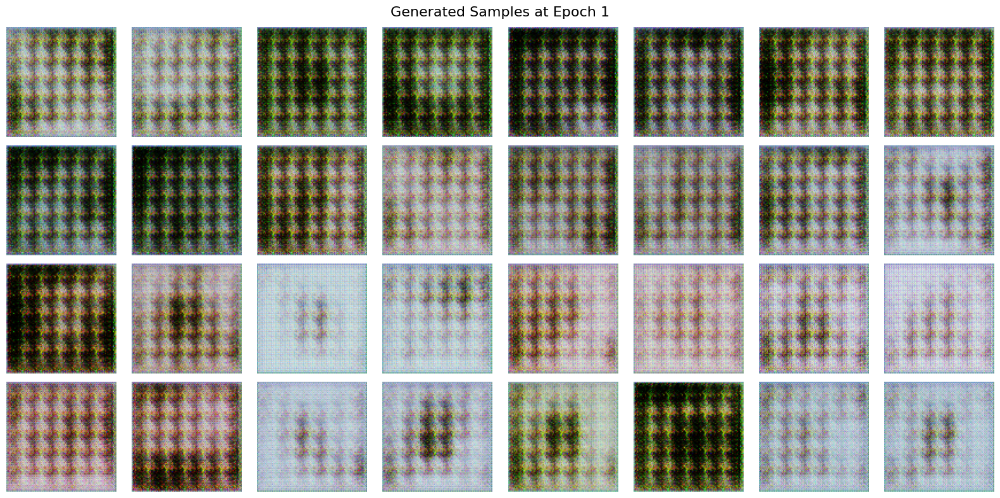

Epoch [2/150]  D_loss: 1.2962  G_loss: 0.7648


Epoch [3/150]  D_loss: 1.3199  G_loss: 0.7955


Epoch [4/150]  D_loss: 1.2901  G_loss: 0.8749


Epoch [5/150]  D_loss: 1.2580  G_loss: 0.9823


Epoch [6/150]  D_loss: 0.8043  G_loss: 2.0081


Epoch [7/150]  D_loss: 0.7378  G_loss: 2.1316


... (19 outputs left out)

Epoch [27/150]  D_loss: 0.6716  G_loss: 2.4114


Epoch [28/150]  D_loss: 0.7819  G_loss: 2.6753


Epoch [29/150]  D_loss: 0.7072  G_loss: 2.0910


Epoch [30/150]  D_loss: 0.8236  G_loss: 2.0279


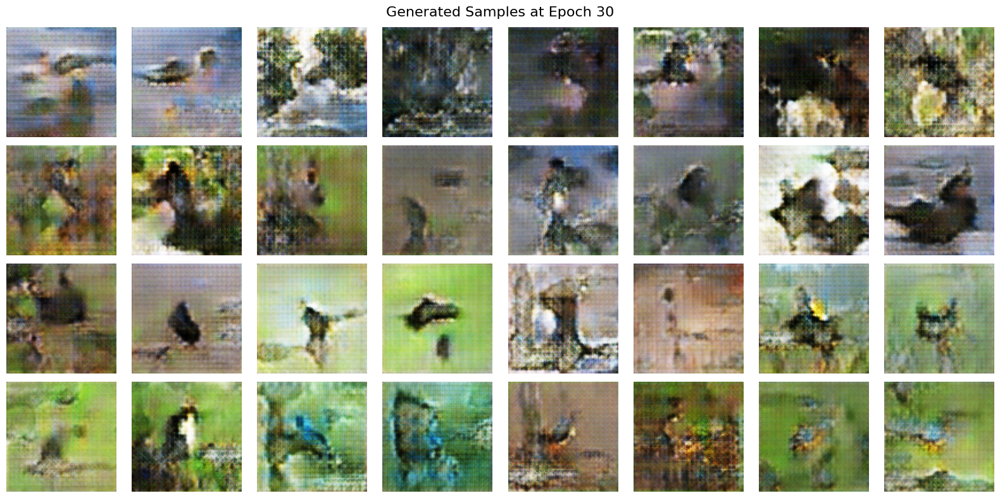

Epoch [31/150]  D_loss: 0.7821  G_loss: 2.6582


Epoch [32/150]  D_loss: 0.6122  G_loss: 2.5015


Epoch [33/150]  D_loss: 0.7303  G_loss: 2.1651


Epoch [34/150]  D_loss: 0.5889  G_loss: 2.3994


Epoch [35/150]  D_loss: 0.6738  G_loss: 2.2642


Epoch [36/150]  D_loss: 0.5985  G_loss: 2.4099


... (20 outputs left out)

Epoch [57/150]  D_loss: 0.4419  G_loss: 2.9556


Epoch [58/150]  D_loss: 0.2532  G_loss: 3.5635


Epoch [59/150]  D_loss: 0.6619  G_loss: 2.5947


Epoch [60/150]  D_loss: 0.5116  G_loss: 3.0860


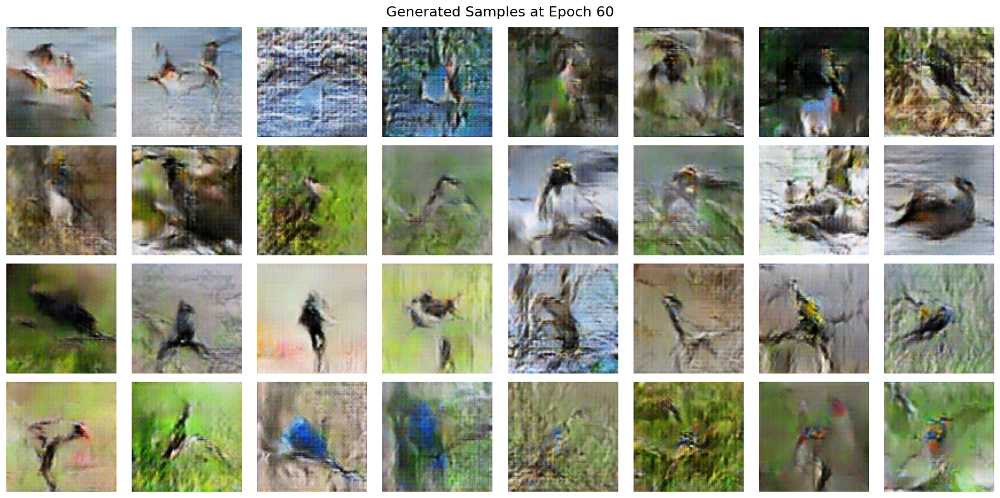

Epoch [61/150]  D_loss: 0.4590  G_loss: 3.3122


Epoch [62/150]  D_loss: 0.6101  G_loss: 3.4425


Epoch [63/150]  D_loss: 0.5533  G_loss: 3.7116


Epoch [64/150]  D_loss: 0.4446  G_loss: 3.3987


Epoch [65/150]  D_loss: 0.3855  G_loss: 3.9652


Epoch [66/150]  D_loss: 0.4743  G_loss: 4.3573


... (20 outputs left out)

Epoch [87/150]  D_loss: 0.3887  G_loss: 5.2287


Epoch [88/150]  D_loss: 0.2448  G_loss: 4.4059


Epoch [89/150]  D_loss: 0.2895  G_loss: 5.3763


Epoch [90/150]  D_loss: 0.2492  G_loss: 4.3802


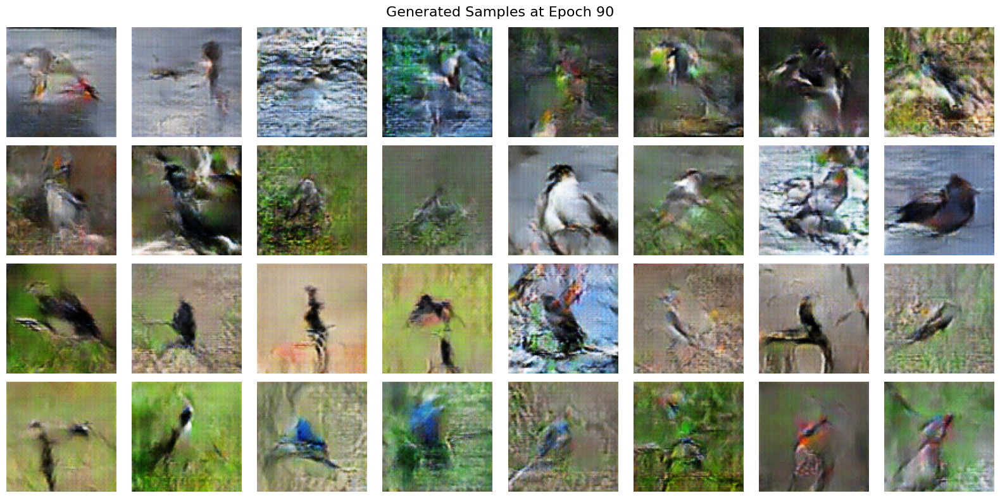

Epoch [91/150]  D_loss: 0.2263  G_loss: 3.9981


Epoch [92/150]  D_loss: 0.2566  G_loss: 5.4241


Epoch [93/150]  D_loss: 0.3553  G_loss: 4.5780


Epoch [94/150]  D_loss: 0.3315  G_loss: 4.5557


Epoch [95/150]  D_loss: 0.5034  G_loss: 5.3065


Epoch [96/150]  D_loss: 0.1680  G_loss: 5.0037


... (20 outputs left out)

Epoch [117/150]  D_loss: 0.2850  G_loss: 5.1101


Epoch [118/150]  D_loss: 0.1747  G_loss: 5.4352


Epoch [119/150]  D_loss: 0.2469  G_loss: 5.4802


Epoch [120/150]  D_loss: 0.1841  G_loss: 6.1290


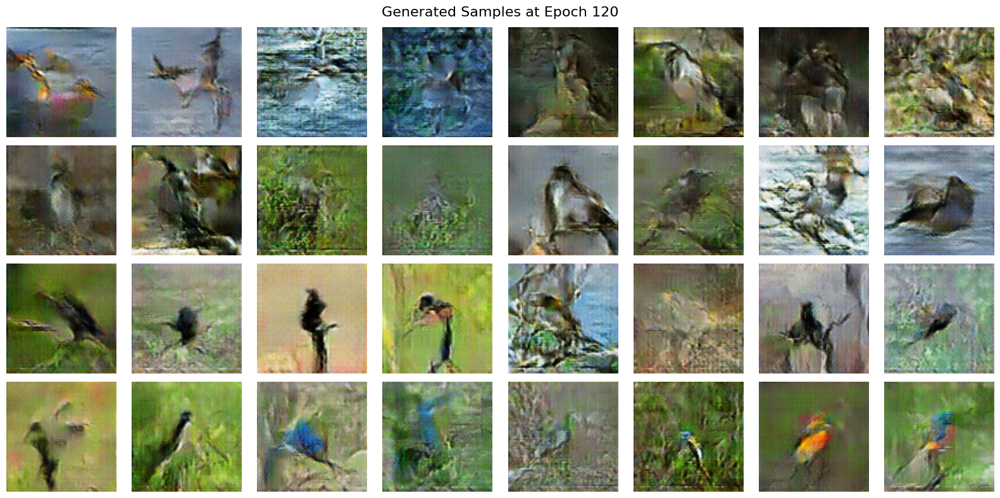

Epoch [121/150]  D_loss: 0.0891  G_loss: 4.1882


Epoch [122/150]  D_loss: 0.1932  G_loss: 5.0000


Epoch [123/150]  D_loss: 0.1680  G_loss: 5.6764


Epoch [124/150]  D_loss: 0.1800  G_loss: 6.9698


Epoch [125/150]  D_loss: 0.4042  G_loss: 6.0387


Epoch [126/150]  D_loss: 0.2010  G_loss: 5.8791


... (20 outputs left out)

Epoch [147/150]  D_loss: 0.2544  G_loss: 5.9912


Epoch [148/150]  D_loss: 0.3101  G_loss: 7.0077


Epoch [149/150]  D_loss: 0.1866  G_loss: 6.6880


Epoch [150/150]  D_loss: 0.1939  G_loss: 5.9857


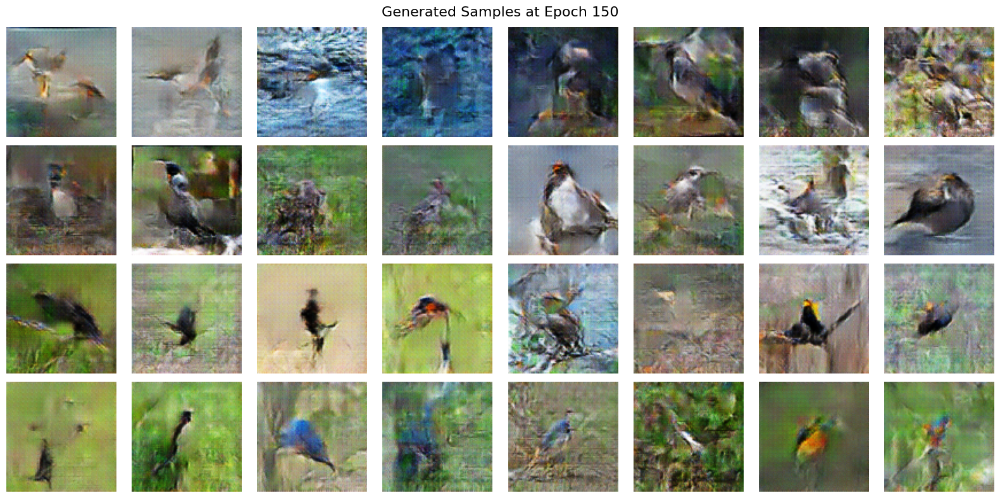

training done and models/losses saved.


In [36]:
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

fixed_z = torch.randn(y_dim * 2, z_dim, device=DEVICE)
fixed_labels = torch.arange(y_dim, device=DEVICE).repeat_interleave(2)
fixed_labels_onehot = make_one_hot(fixed_labels, y_dim)

D_losses = []
G_losses = []

for epoch in range(1, epochs + 1):
    loop = tqdm(cub_loader, leave=False, desc=f"Epoch {epoch}/{epochs}")
    for real_imgs, labels in loop:
        real_imgs, labels = real_imgs.to(DEVICE), labels.to(DEVICE)
        bsize = real_imgs.size(0)

        real_targets = torch.ones(bsize, 1, device=DEVICE)
        fake_targets = torch.zeros(bsize, 1, device=DEVICE)

        labels_onehot = make_one_hot(labels, y_dim)

        D_optimizer.zero_grad()
        D_real = D(real_imgs, labels_onehot)
        D_loss_real = criterion(D_real, real_targets)

        z = torch.randn(bsize, z_dim, device=DEVICE)
        fake_imgs = G(z, labels_onehot)
        D_fake = D(fake_imgs.detach(), labels_onehot)
        D_loss_fake = criterion(D_fake, fake_targets)

        D_loss = D_loss_real + D_loss_fake
        D_loss.backward()
        D_optimizer.step()

        G_optimizer.zero_grad()
        z = torch.randn(bsize, z_dim, device=DEVICE)
        fake_imgs = G(z, labels_onehot)
        D_fake = D(fake_imgs, labels_onehot)
        G_loss = criterion(D_fake, real_targets)

        G_loss.backward()
        G_optimizer.step()

        D_losses.append(D_loss.item())
        G_losses.append(G_loss.item())

    print(f"Epoch [{epoch}/{epochs}]  D_loss: {D_loss.item():.4f}  G_loss: {G_loss.item():.4f}")

    if epoch % 30 == 0 or epoch == 1:
        with torch.no_grad():
            fake_imgs_fixed = G(fixed_z, fixed_labels_onehot)

        save_image_grid(fake_imgs_fixed, fixed_labels, epoch, save_dir)

        fig, axes = plt.subplots(4, 8, figsize=(16, 8))
        axes = axes.flatten()
        fake_imgs_fixed = fake_imgs_fixed.detach().cpu()
        fake_imgs_fixed = (fake_imgs_fixed + 1) / 2

        for img, ax in zip(fake_imgs_fixed, axes):
            img = img.permute(1, 2, 0)
            ax.imshow(img)
            ax.axis('off')

        for ax in axes[len(fake_imgs_fixed):]:
            ax.axis('off')

        plt.suptitle(f"Generated Samples at Epoch {epoch}", fontsize=16)
        plt.tight_layout()
        plt.show()

np.save(os.path.join(save_dir, "D_losses.npy"), np.array(D_losses))
np.save(os.path.join(save_dir, "G_losses.npy"), np.array(G_losses))
torch.save(G.state_dict(), os.path.join(save_dir, "generator.pth"))
torch.save(D.state_dict(), os.path.join(save_dir, "discriminator.pth"))

print("training done and models/losses saved.")

## Class-Wise Generation: Semantic Coverage Across CUB-200

This section performs a **class-wise qualitative evaluation** of the trained CUB-200 label-conditioned robot vision module by generating **one synthetic bird image per semantic class**.

This evaluates **semantic coverage** rather than visual fidelity. The goal is to verify whether the perception module can produce a **distinct visual hypothesis for every class** in a large and fine-grained semantic space (200 bird species).

### What This Evaluation Tests
- **Semantic reachability**: whether each label in the 200-class space maps to a non-degenerate visual output.
- **Class isolation**: whether generated samples vary meaningfully across labels instead of collapsing to a few modes.
- **Scalability of conditioning**: whether explicit semantic priors remain effective as class count increases.

### Interpretation of Results
- The generated images exhibit significant variability in color, texture, and structure across classes, indicating that the generator has internalized **class-level visual cues**.
- Visual sharpness and anatomical correctness are limited, which is expected given:
  - the fixed 96×96 resolution,
  - the complexity of fine-grained bird categories,
  - and the absence of explicit spatial or part-based supervision.
- Some classes may appear visually similar or noisy, highlighting common failure modes such as **class entanglement** and **background leakage**.

### Relevance
In robotic perception pipelines, such class-wise visualization serves as a **diagnostic tool**:
- to confirm that semantic conditioning spans the full label space,
- to identify categories where perception is unreliable,
- and to guide architectural or data-centric improvements.

This experiment demonstrates that the vision module maintains **semantic controllability at scale**, even under the most challenging dataset considered in this project.

C:\Users\aymisxx\AppData\Local\Temp\ipykernel_10568\390559494.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  G.load_state_dict(torch.load(os.path.join(save_dir, "genera

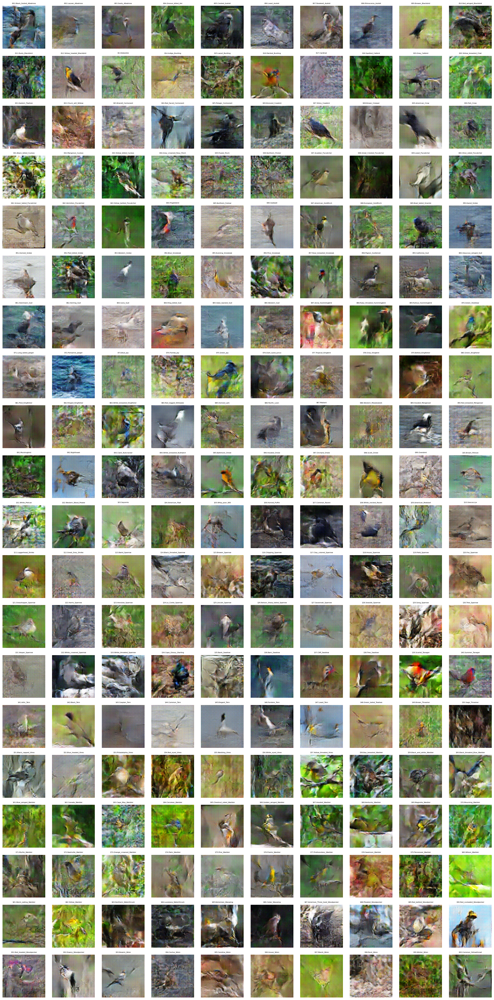

In [37]:
import torch
import matplotlib.pyplot as plt
import math

# Load the trained Generator
G = Generator96().to(DEVICE)
G.load_state_dict(torch.load(os.path.join(save_dir, "generator.pth")))
G.eval()

# Load class names
cub_classes = []
with open(os.path.join(cub_root, "classes.txt")) as f:
    for line in f:
        cub_classes.append(line.strip().split(" ", 1)[1])

# Generate one bird per class
def generate_bird_for_each_class():
    z = torch.randn(y_dim, z_dim, device=DEVICE)  # 200 random noise vectors
    labels = torch.arange(y_dim, device=DEVICE)   # Labels 0 to 199
    labels_onehot = make_one_hot(labels, y_dim)

    with torch.no_grad():
        fake_imgs = G(z, labels_onehot)

    fake_imgs = (fake_imgs + 1) / 2  # Denormalize
    fake_imgs = fake_imgs.detach().cpu()

    # Plotting
    ncols = 10
    nrows = math.ceil(y_dim / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2, nrows * 2))
    axes = axes.flatten()

    for img, label, ax in zip(fake_imgs, labels, axes):
        img = img.permute(1, 2, 0)
        ax.imshow(img)
        ax.set_title(cub_classes[label], fontsize=5)
        ax.axis('off')

    for ax in axes[len(fake_imgs):]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Call the function
generate_bird_for_each_class()

## CUB-200 Bird Classes: Index → Semantic Label Mapping

Each index corresponds to a unique semantic class used for label-conditioned robot vision.

1. Black_Footed_Albatross  
2. Laysan_Albatross  
3. Sooty_Albatross  
4. Groove_Billed_Ani  
5. Crested_Auklet  
6. Least_Auklet  
7. Parakeet_Auklet  
8. Rhinoceros_Auklet  
9. Brewer_Blackbird  
10. Red_Winged_Blackbird  
11. Rusty_Blackbird  
12. Yellow_Headed_Blackbird  
13. Bobolink  
14. Indigo_Bunting  
15. Lazuli_Bunting  
16. Painted_Bunting  
17. Cardinal  
18. Spotted_Catbird  
19. Gray_Catbird  
20. Yellow_Breasted_Chat  
21. Eastern_Towhee  
22. Chuck_Will_Widow  
23. Brandt_Cormorant  
24. Red_Faced_Cormorant  
25. Pelagic_Cormorant  
26. Bronzed_Cowbird  
27. Shiny_Cowbird  
28. Brown_Creeper  
29. American_Crow  
30. Fish_Crow  
31. Black_Billed_Cuckoo  
32. Mangrove_Cuckoo  
33. Yellow_Billed_Cuckoo  
34. Gray_Crowned_Rosy_Finch  
35. Purple_Finch  
36. Northern_Flicker  
37. Acadian_Flycatcher  
38. Great_Crested_Flycatcher  
39. Least_Flycatcher  
40. Olive_Sided_Flycatcher  
41. Scissor_Tailed_Flycatcher  
42. Vermilion_Flycatcher  
43. Yellow_Bellied_Flycatcher  
44. Frigatebird  
45. Northern_Fulmar  
46. Gadwall  
47. American_Goldfinch  
48. European_Goldfinch  
49. Boat_Tailed_Grackle  
50. Eared_Grebe  
51. Horned_Grebe  
52. Pied_Billed_Grebe  
53. Western_Grebe  
54. Blue_Grosbeak  
55. Evening_Grosbeak  
56. Pine_Grosbeak  
57. Rose_Breasted_Grosbeak  
58. Pigeon_Guillemot  
59. California_Gull  
60. Glaucous_Winged_Gull  
61. Heermann_Gull  
62. Herring_Gull  
63. Ivory_Gull  
64. Ring_Billed_Gull  
65. Slaty_Backed_Gull  
66. Western_Gull  
67. Anna_Hummingbird  
68. Ruby_Throated_Hummingbird  
69. Rufous_Hummingbird  
70. Green_Violetear  
71. Long_Tailed_Jaeger  
72. Pomarine_Jaeger  
73. Blue_Jay  
74. Florida_Jay  
75. Green_Jay  
76. Dark_Eyed_Junco  
77. Northern_Jacana  
78. Green_Kingfisher  
79. Pied_Kingfisher  
80. Ringed_Kingfisher  
81. Belted_Kingfisher  
82. White_Breasted_Kingfisher  
83. Red_Legged_Kittiwake  
84. Horned_Lark  
85. Pacific_Loon  
86. Mallard  
87. Western_Meadowlark  
88. Hooded_Merganser  
89. Red_Breasted_Merganser  
90. Mockingbird  
91. Nighthawk  
92. Clark_Nutcracker  
93. White_Breasted_Nuthatch  
94. Baltimore_Oriole  
95. Hooded_Oriole  
96. Orchard_Oriole  
97. Scott_Oriole  
98. Ovenbird  
99. Brown_Pelican  
100. White_Pelican  
101. Western_Wood_Pewee  
102. Sayornis  
103. American_Pipit  
104. Whip_Poor_Will  
105. Horned_Puffin  
106. Common_Raven  
107. White_Necked_Raven  
108. American_Redstart  
109. Geococcyx  
110. Loggerhead_Shrike  
111. Great_Grey_Shrike  
112. Baird_Sparrow  
113. Black_Throated_Sparrow  
114. Brewer_Sparrow  
115. Chipping_Sparrow  
116. Clay_Colored_Sparrow  
117. House_Sparrow  
118. Field_Sparrow  
119. Fox_Sparrow  
120. Grasshopper_Sparrow  
121. Harris_Sparrow  
122. Henslow_Sparrow  
123. Le_Conte_Sparrow  
124. Lincoln_Sparrow  
125. Nelson_Sharp_Tailed_Sparrow  
126. Savannah_Sparrow  
127. Seaside_Sparrow  
128. Song_Sparrow  
129. Tree_Sparrow  
130. Vesper_Sparrow  
131. White_Crowned_Sparrow  
132. White_Throated_Sparrow  
133. Cape_Glossy_Starling  
134. Bank_Swallow  
135. Barn_Swallow  
136. Cliff_Swallow  
137. Tree_Swallow  
138. Scarlet_Tanager  
139. Summer_Tanager  
140. Artic_Tern  
141. Black_Tern  
142. Caspian_Tern  
143. Common_Tern  
144. Elegant_Tern  
145. Forsters_Tern  
146. Least_Tern  
147. Green_Tailed_Towhee  
148. Brown_Thrasher  
149. Sage_Thrasher  
150. Black_Capped_Vireo  
151. Blue_Headed_Vireo  
152. Philadelphia_Vireo  
153. Red_Eyed_Vireo  
154. Warbling_Vireo  
155. White_Eyed_Vireo  
156. Yellow_Throated_Vireo  
157. Bay_Breasted_Warbler  
158. Black_And_White_Warbler  
159. Black_Throated_Blue_Warbler  
160. Blue_Winged_Warbler  
161. Canada_Warbler  
162. Cape_May_Warbler  
163. Cerulean_Warbler  
164. Chestnut_Sided_Warbler  
165. Golden_Winged_Warbler  
166. Hooded_Warbler  
167. Kentucky_Warbler  
168. Magnolia_Warbler  
169. Mourning_Warbler  
170. Myrtle_Warbler  
171. Nashville_Warbler  
172. Orange_Crowned_Warbler  
173. Palm_Warbler  
174. Pine_Warbler  
175. Prairie_Warbler  
176. Prothonotary_Warbler  
177. Swainson_Warbler  
178. Tennessee_Warbler  
179. Wilson_Warbler  
180. Worm_Eating_Warbler  
181. Yellow_Warbler  
182. Northern_Waterthrush  
183. Louisiana_Waterthrush  
184. Bohemian_Waxwing  
185. Cedar_Waxwing  
186. American_Three_Toed_Woodpecker  
187. Downy_Woodpecker  
188. Hairy_Woodpecker  
189. Red_Bellied_Woodpecker  
190. Red_Cockaded_Woodpecker  
191. Pileated_Woodpecker  
192. Red_Headed_Woodpecker  
193. White_Breasted_Woodpecker  
194. American_Three_Toed_Woodpecker  
195. Bewick_Wren  
196. Cactus_Wren  
197. Carolina_Wren  
198. House_Wren  
199. Marsh_Wren  
200. Rock_Wren

#### **We will be entering (target label = (corresponding number - 1)) for the bird we want to generate.**

## Class-Specific Grounding: Real vs Generated Comparisons (CUB-200)

This section performs **targeted semantic grounding checks** on the CUB-200 dataset using a small set of representative bird classes.

This evaluates whether the perception module can:
- respect a **specific semantic prior** (class label),
- generate a plausible visual hypothesis consistent with that label,
- and maintain class-level separation in a **fine-grained, high-cardinality setting**.

For each selected class, we:
1. randomly sample a **real image** from the dataset,
2. generate a **synthetic image** conditioned on the same class label,
3. visualize both **side-by-side** for direct qualitative comparison.

This type of class-specific inspection is critical in robotics, where perception systems must be **interpretable and diagnosable** at the level of individual semantic categories rather than only aggregate statistics.

C:\Users\aymisxx\AppData\Local\Temp\ipykernel_10568\80036120.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  G.load_state_dict(torch.load(os.path.join(save_dir, "generat

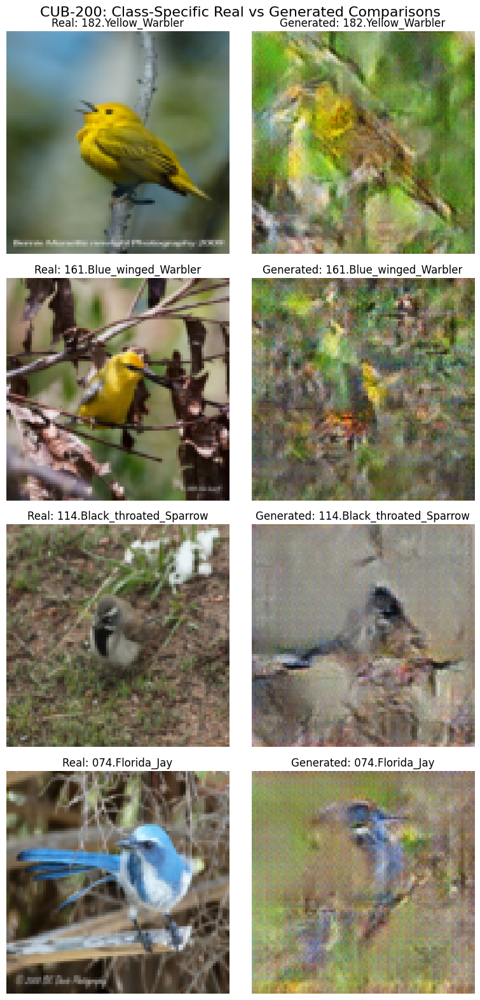

In [38]:
import torch
import matplotlib.pyplot as plt
import random
from PIL import Image
import os

# Load trained Generator
G = Generator96().to(DEVICE)
G.load_state_dict(torch.load(os.path.join(save_dir, "generator.pth"), map_location=DEVICE))
G.eval()

# Load class names
with open(os.path.join(cub_root, "classes.txt")) as f:
    class_names = [line.strip().split(" ", 1)[1] for line in f.readlines()]

# Selected examples: (label, name for clarity)
target_examples = [
    (181, "Yellow Warbler"),
    (160, "Blue-winged Warbler"),
    (113, "Black-throated Sparrow"),
    (73,  "Florida Jay"),
]

fig, axes = plt.subplots(len(target_examples), 2, figsize=(8, 4 * len(target_examples)))

for row, (target_label, _) in enumerate(target_examples):

    # Real image
    real_indices = [i for i, lbl in enumerate(cub_dataset.labels) if lbl == target_label]
    real_idx = random.choice(real_indices)
    real_img_path = os.path.join(cub_root, "images", cub_dataset.image_paths[real_idx])

    real_img = Image.open(real_img_path).convert("RGB")
    real_img = transform(real_img)
    real_img = (real_img + 1) / 2
    real_img = real_img.permute(1, 2, 0).cpu()

    # Generated image
    z = torch.randn(1, z_dim, device=DEVICE)
    label_tensor = torch.tensor([target_label], device=DEVICE)
    label_onehot = make_one_hot(label_tensor, y_dim)

    with torch.no_grad():
        fake_img = G(z, label_onehot)

    fake_img = (fake_img + 1) / 2
    fake_img = fake_img.squeeze(0).permute(1, 2, 0).cpu()

    # Plot
    axes[row, 0].imshow(real_img)
    axes[row, 0].set_title(f"Real: {class_names[target_label]}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(fake_img)
    axes[row, 1].set_title(f"Generated: {class_names[target_label]}")
    axes[row, 1].axis("off")

plt.suptitle("CUB-200: Class-Specific Real vs Generated Comparisons", fontsize=16)
plt.tight_layout()
plt.show()

## Interpretation of CUB-200 Results: Semantic Consistency Under Environmental Complexity

The CUB-200 results demonstrate that the label-conditioned robot vision model is able to capture **class-level semantic cues**, particularly **dominant color distributions and coarse object presence**, despite operating in a highly challenging visual regime.

Unlike MNIST or Oxford-102, the CUB-200 dataset contains:
- complex and highly variable **background elements** (branches, foliage, water bodies, sky, man-made structures),
- significant **pose variation** (perching, flying, standing),
- and fine-grained inter-class differences that are often subtle even for human observers.

Within this context, the generated images consistently reflect **class-relevant color priors** (e.g., yellow hues for Yellow Warbler, blue tones for Florida Jay), indicating that semantic conditioning remains effective. However, background textures and scene statistics are strongly entangled with the foreground object, leading to blurred or abstract representations.

From a robotics perspective, this outcome is expected and informative:
- The model prioritizes **global semantic alignment** over fine anatomical detail.
- Environmental context is treated as part of the visual distribution, mirroring how real robotic sensors often observe objects embedded within cluttered scenes.
- The results highlight the difficulty of fine-grained object synthesis without explicit spatial, part-based, or attention-driven inductive biases.

Overall, these outputs confirm that the vision module learns **meaningful semantic associations** under complex environmental conditions, while clearly exposing the limits of baseline conditional generative models for fine-grained perception tasks.

# **Final Summary and Takeaways**

This project investigated **label-conditioned robot vision** across three progressively challenging perception regimes: MNIST, Oxford-102 Flowers, and CUB-200 Birds.

Key takeaways:
- **MNIST** validated the core conditioning mechanism, demonstrating reliable semantic controllability in a low-entropy setting.
- **Oxford-102** extended the framework to real-world imagery, showing that the model can learn color- and texture-dominated semantics under moderate visual complexity.
- **CUB-200** served as a stress test for fine-grained perception, revealing that while class-level semantic cues are preserved, detailed structural reconstruction degrades under high semantic cardinality and complex backgrounds.

From a Robotics & Autonomous Systems standpoint, these results are both realistic and valuable. They illustrate how generative perception models behave when confronted with increasing environmental variability and semantic density—conditions typical of real robotic sensing.

The project intentionally emphasizes **interpretability and failure analysis** over photorealism. By exposing where and why semantic conditioning succeeds or breaks down, this work provides a clear foundation for future extensions, including attention-based architectures, diffusion models, and structured spatial priors.

In summary, this study establishes a principled baseline for label-conditioned robot vision and offers concrete insights into the challenges of scaling generative perception to complex, real-world environments.